In [1]:
import glob
import os

subDir = os.listdir('DandiSetData/000008/')
subDir = [_dir for _dir in subDir if os.path.isdir('DandiSetData/000008/'+_dir)]
nwb_data = []
for _dir in subDir:
    _files = glob.glob('DandiSetData/000008/'+_dir+'/*.nwb')
    nwb_data += _files

In [2]:
nwb_data

['DandiSetData/000008/sub-mouse-DAEWZ/sub-mouse-DAEWZ_ses-20181208-sample-3_slice-20181208-slice-2_cell-20181208-sample-3_icephys.nwb',
 'DandiSetData/000008/sub-mouse-DAEWZ/sub-mouse-DAEWZ_ses-20181208-sample-2_slice-20181208-slice-1_cell-20181208-sample-2_icephys.nwb',
 'DandiSetData/000008/sub-mouse-DAEWZ/sub-mouse-DAEWZ_ses-20181208-sample-6_slice-20181208-slice-3_cell-20181208-sample-6_icephys.nwb',
 'DandiSetData/000008/sub-mouse-DAEWZ/sub-mouse-DAEWZ_ses-20181208-sample-5_slice-20181208-slice-3_cell-20181208-sample-5_icephys.nwb',
 'DandiSetData/000008/sub-mouse-DAEWZ/sub-mouse-DAEWZ_ses-20181208-sample-1_slice-20181208-slice-1_cell-20181208-sample-1_icephys.nwb',
 'DandiSetData/000008/sub-mouse-DAEWZ/sub-mouse-DAEWZ_ses-20181208-sample-7_slice-20181208-slice-4_cell-20181208-sample-7_icephys.nwb',
 'DandiSetData/000008/sub-mouse-DAEWZ/sub-mouse-DAEWZ_ses-20181208-sample-10_slice-20181208-slice-6_cell-20181208-sample-10_icephys.nwb',
 'DandiSetData/000008/sub-mouse-DAEWZ/sub-mous

In [3]:
len(nwb_data)

1328

In [4]:
import re

id_to_path = {}

pattern = re.compile(r"cell-(\d{8})-sample-(\d+)")  
# captures: group(1) = date, group(2) = sample number

for path in nwb_data:
    m = pattern.search(path)
    if m:
        date = m.group(1)
        sample = m.group(2)
        cell_id = f"{date}_sample_{sample}"
        id_to_path[cell_id] = path

print("Indexed:", len(id_to_path), "cells")

Indexed: 1328 cells


In [5]:
id_to_path['20180918_sample_1']

'DandiSetData/000008/sub-mouse-KVPGJ/sub-mouse-KVPGJ_ses-20180918-sample-1_slice-20180918-slice-1_cell-20180918-sample-1_icephys.nwb'

In [7]:
import pandas as pd

meta = pd.read_csv(
    "PatchSeqExpression/m1_patchseq_meta_data.csv",
    sep=None,          # let pandas sniff the delimiter
    engine="python"    # required when sep=None
)

print(meta.head())
print(meta.columns)

   Number               Cell             Slice        Date    Sample  \
0       1  20171204_sample_2  20171204_slice_2  2017-12-04  sample 2   
1       2  20171204_sample_4  20171204_slice_4  2017-12-04  sample 4   
2       3  20171204_sample_5  20171204_slice_5  2017-12-04  sample 5   
3       4  20171204_sample_6  20171204_slice_6  2017-12-04  sample 6   
4       5  20171207_sample_1  20171207_slice_1  2017-12-07  sample 1   

         Mouse Mouse date of birth  Mouse age Mouse gender  \
0  mouse_GTOKH          2017-10-29         36            M   
1  mouse_GTOKH          2017-10-29         36            M   
2  mouse_GTOKH          2017-10-29         36            M   
3  mouse_GTOKH          2017-10-29         36            M   
4  mouse_UGZSW          2017-09-18         80            F   

            Mouse genotype  ... Length (bp) Yield (pg/µl)  User  \
0     Pvalb-Cre/wt; Ai9/wt  ...        1955         95.19  Fede   
1     Pvalb-Cre/wt; Ai9/wt  ...        1887         80.22  F

In [8]:
import pandas as pd
import numpy as np

# ---------- 0) Load metadata ----------
meta = pd.read_csv(
    "PatchSeqExpression/m1_patchseq_meta_data.csv",
    sep=None,
    engine="python"
)

# Standardize id and RNA type
meta["Cell"] = meta["Cell"].astype(str).str.strip()
meta["RNA type"] = meta["RNA type"].astype(str).str.strip()

# L5 excitatory = entries starting with "L5 " (e.g. "L5 ET_1", "L5 IT_2")
rna = meta["RNA type"].astype(str).str.strip()

mask_l5_exc = (
    rna.str.startswith("L5 IT_") |
    rna.str.startswith("L5 ET_")
)

l5_exc_ids = meta.loc[mask_l5_exc, "Cell"].astype(str).str.strip().unique()

print("True L5 excitatory cells:", len(l5_exc_ids))
print(pd.Series(rna[mask_l5_exc]).value_counts())

# ---------- 1) Load counts & compute logCPM ----------
counts = pd.read_csv(
    "PatchSeqExpression/GSE163764_m1_patchseq_exon_counts.csv",
    index_col=0
)

expr = counts.T
expr.index = expr.index.astype(str).str.strip()

libsize = expr.sum(axis=1)
cpm = expr.div(libsize, axis=0) * 1e6
log_cpm = np.log1p(cpm)

# ---------- 2) Restrict to L5 excitatory cells ----------
log_cpm_l5 = log_cpm.loc[log_cpm.index.intersection(l5_exc_ids)]
print("log_cpm_l5 shape (cells × genes):", log_cpm_l5.shape)

# ---------- 3) (Optional) Plasticity genes within L5 ----------
genes_of_interest = [
    "FOS","FOSB","FOSL1","FOSL2","JUN","JUNB","JUND","EGR1","EGR2","EGR3","EGR4",
    "NPAS4","KLF2","KLF4","KLF6","KLF9","KLF10","KLF11","ATF3","ATF4","ATF5","ATF7",
    "CREM","CREB1","CREB3","CREB5","SRF","ELK1","ELK3","ELK4","NR4A1","NR4A2","NR4A3",
    "BTG1","BTG2","IER2","IER3","IER5","ARC","HOMER1","BDNF","NPTX2","NPTX1","NPTXR",
    "SYT4","CAMK2G","CAMK1G","CAMK4","MAPK8IP2","MAPK1IP1L",
    "RGS2","RGS4","RGS14","DUSP1","DUSP4","DUSP5","DUSP6",
    "PPP1R1B","PPP1R15A","PLK2","PLK3","PRKCZ","PRKCI","RAPGEF4","RAPGEF5","RAPGEF3",
    "GADD45A","GADD45B","GADD45G","DNMT3A","DNMT3B","MECP2","HDAC4","HDAC5","HDAC9",
    "RCAN1","RCAN2","RCAN3","CALN1","CALM1","CALM2","CALM3",
    "CAMKK1","CAMKK2","AKAP5","AKAP6","AKAP11","AKAP12","AKAP13",
    "HSPB1","HSPA1A","HSPA1B","DDIT3","CHAC1","TRIB1","TRIB2","TRIB3",
    "SGK1","SGK3","SERTAD1","SERTAD2","SERTAD3",
    "BAIAP2","BAIAP3","SIPA1L1","SIPA1L2","SYNPO","SYNPO2","SYNGAP1",
    "DLG4","DLG3","SHANK1","SHANK2","SHANK3",
    "RHOA","RHOB","RHOC","RHOU","RND1","RND2","RND3",
    "MAPK8","MAPK10","MAPT","RASGRF1","RASGRF2","RAP1GAP","RAP1GDS1",
    "PAK1","PAK3"
]

genes_of_interest =  [g[0]+ g[1:].lower() for g in genes_of_interest]
present = [g for g in genes_of_interest if g in log_cpm_l5.columns]
print("Present plasticity genes:", present)

X = log_cpm_l5[present]
Xz = (X - X.mean(axis=0)) / X.std(axis=0)
plasticity_score_l5 = Xz.mean(axis=1)   # Series indexed by L5-exc cell IDs


True L5 excitatory cells: 126
RNA type
L5 IT_1    59
L5 ET_1    32
L5 ET_4     9
L5 IT_2     7
L5 IT_3     7
L5 ET_2     4
L5 ET_3     4
L5 IT_4     4
Name: count, dtype: int64
log_cpm_l5 shape (cells × genes): (126, 42466)
Present plasticity genes: ['Fos', 'Fosb', 'Fosl1', 'Fosl2', 'Jun', 'Junb', 'Jund', 'Egr1', 'Egr2', 'Egr3', 'Egr4', 'Npas4', 'Klf2', 'Klf4', 'Klf6', 'Klf9', 'Klf10', 'Klf11', 'Atf3', 'Atf4', 'Atf5', 'Crem', 'Creb1', 'Creb3', 'Creb5', 'Srf', 'Elk1', 'Elk3', 'Elk4', 'Nr4a1', 'Nr4a2', 'Nr4a3', 'Btg1', 'Btg2', 'Ier2', 'Ier3', 'Ier5', 'Arc', 'Homer1', 'Bdnf', 'Nptx2', 'Nptx1', 'Nptxr', 'Syt4', 'Camk2g', 'Camk1g', 'Camk4', 'Mapk8ip2', 'Mapk1ip1l', 'Rgs2', 'Rgs4', 'Rgs14', 'Dusp1', 'Dusp4', 'Dusp5', 'Dusp6', 'Ppp1r1b', 'Ppp1r15a', 'Plk2', 'Plk3', 'Prkcz', 'Prkci', 'Rapgef4', 'Rapgef5', 'Rapgef3', 'Gadd45a', 'Gadd45b', 'Gadd45g', 'Dnmt3a', 'Dnmt3b', 'Mecp2', 'Hdac4', 'Hdac5', 'Hdac9', 'Rcan1', 'Rcan2', 'Rcan3', 'Caln1', 'Calm1', 'Calm2', 'Calm3', 'Camkk1', 'Camkk2', 'Akap5',

In [9]:
genes_of_interest

['Fos',
 'Fosb',
 'Fosl1',
 'Fosl2',
 'Jun',
 'Junb',
 'Jund',
 'Egr1',
 'Egr2',
 'Egr3',
 'Egr4',
 'Npas4',
 'Klf2',
 'Klf4',
 'Klf6',
 'Klf9',
 'Klf10',
 'Klf11',
 'Atf3',
 'Atf4',
 'Atf5',
 'Atf7',
 'Crem',
 'Creb1',
 'Creb3',
 'Creb5',
 'Srf',
 'Elk1',
 'Elk3',
 'Elk4',
 'Nr4a1',
 'Nr4a2',
 'Nr4a3',
 'Btg1',
 'Btg2',
 'Ier2',
 'Ier3',
 'Ier5',
 'Arc',
 'Homer1',
 'Bdnf',
 'Nptx2',
 'Nptx1',
 'Nptxr',
 'Syt4',
 'Camk2g',
 'Camk1g',
 'Camk4',
 'Mapk8ip2',
 'Mapk1ip1l',
 'Rgs2',
 'Rgs4',
 'Rgs14',
 'Dusp1',
 'Dusp4',
 'Dusp5',
 'Dusp6',
 'Ppp1r1b',
 'Ppp1r15a',
 'Plk2',
 'Plk3',
 'Prkcz',
 'Prkci',
 'Rapgef4',
 'Rapgef5',
 'Rapgef3',
 'Gadd45a',
 'Gadd45b',
 'Gadd45g',
 'Dnmt3a',
 'Dnmt3b',
 'Mecp2',
 'Hdac4',
 'Hdac5',
 'Hdac9',
 'Rcan1',
 'Rcan2',
 'Rcan3',
 'Caln1',
 'Calm1',
 'Calm2',
 'Calm3',
 'Camkk1',
 'Camkk2',
 'Akap5',
 'Akap6',
 'Akap11',
 'Akap12',
 'Akap13',
 'Hspb1',
 'Hspa1a',
 'Hspa1b',
 'Ddit3',
 'Chac1',
 'Trib1',
 'Trib2',
 'Trib3',
 'Sgk1',
 'Sgk3',
 'Sertad1',
 '

In [10]:
plasticity_score_l5

20171204_sample_2   -0.261666
20171204_sample_4   -0.341853
20171204_sample_5    0.429072
20171204_sample_6    0.075180
20171207_sample_1    0.233232
                       ...   
20191114_sample_7   -0.336789
20191114_sample_8   -0.421897
20191114_sample_9   -0.947324
20200106_sample_5   -1.096428
20200316_sample_1   -0.918841
Length: 126, dtype: float64

In [11]:
import pandas as pd
import numpy as np

# 1) Load counts with genes as index, cells as columns
counts = pd.read_csv("PatchSeqExpression/GSE163764_m1_patchseq_exon_counts.csv", index_col=0)
# counts: genes × cells

# 2) Transpose to cells × genes (what your code expects)
expr = counts.T  # cells × genes

# 3) Library-size normalize → logCPM
libsize = expr.sum(axis=1)
cpm = expr.div(libsize, axis=0) * 1e6
log_cpm = np.log1p(cpm)

# 4) Plasticity genes
genes_of_interest = [
    "FOS","FOSB","FOSL1","FOSL2","JUN","JUNB","JUND","EGR1","EGR2","EGR3","EGR4",
    "NPAS4","KLF2","KLF4","KLF6","KLF9","KLF10","KLF11","ATF3","ATF4","ATF5","ATF7",
    "CREM","CREB1","CREB3","CREB5","SRF","ELK1","ELK3","ELK4","NR4A1","NR4A2","NR4A3",
    "BTG1","BTG2","IER2","IER3","IER5","ARC","HOMER1","BDNF","NPTX2","NPTX1","NPTXR",
    "SYT4","CAMK2G","CAMK1G","CAMK4","MAPK8IP2","MAPK1IP1L",
    "RGS2","RGS4","RGS14","DUSP1","DUSP4","DUSP5","DUSP6",
    "PPP1R1B","PPP1R15A","PLK2","PLK3","PRKCZ","PRKCI","RAPGEF4","RAPGEF5","RAPGEF3",
    "GADD45A","GADD45B","GADD45G","DNMT3A","DNMT3B","MECP2","HDAC4","HDAC5","HDAC9",
    "RCAN1","RCAN2","RCAN3","CALN1","CALM1","CALM2","CALM3",
    "CAMKK1","CAMKK2","AKAP5","AKAP6","AKAP11","AKAP12","AKAP13",
    "HSPB1","HSPA1A","HSPA1B","DDIT3","CHAC1","TRIB1","TRIB2","TRIB3",
    "SGK1","SGK3","SERTAD1","SERTAD2","SERTAD3",
    "BAIAP2","BAIAP3","SIPA1L1","SIPA1L2","SYNPO","SYNPO2","SYNGAP1",
    "DLG4","DLG3","SHANK1","SHANK2","SHANK3",
    "RHOA","RHOB","RHOC","RHOU","RND1","RND2","RND3",
    "MAPK8","MAPK10","MAPT","RASGRF1","RASGRF2","RAP1GAP","RAP1GDS1",
    "PAK1","PAK3"
]

genes_of_interest =  [g[0]+ g[1:].lower() for g in genes_of_interest]
present = [g for g in genes_of_interest if g in log_cpm.columns]
print("Present genes:", present)

# 5) Compute z-scores gene-wise and the plasticity score
X = log_cpm[present]
Xz = (X - X.mean(axis=0)) / X.std(axis=0)
plasticity_score = Xz.mean(axis=1)

# Attach to your obs (or just keep as a Series for now)
#adata.obs["plasticity_score"] = plasticity_score.reindex(adata.obs_names)


Present genes: ['Fos', 'Fosb', 'Fosl1', 'Fosl2', 'Jun', 'Junb', 'Jund', 'Egr1', 'Egr2', 'Egr3', 'Egr4', 'Npas4', 'Klf2', 'Klf4', 'Klf6', 'Klf9', 'Klf10', 'Klf11', 'Atf3', 'Atf4', 'Atf5', 'Crem', 'Creb1', 'Creb3', 'Creb5', 'Srf', 'Elk1', 'Elk3', 'Elk4', 'Nr4a1', 'Nr4a2', 'Nr4a3', 'Btg1', 'Btg2', 'Ier2', 'Ier3', 'Ier5', 'Arc', 'Homer1', 'Bdnf', 'Nptx2', 'Nptx1', 'Nptxr', 'Syt4', 'Camk2g', 'Camk1g', 'Camk4', 'Mapk8ip2', 'Mapk1ip1l', 'Rgs2', 'Rgs4', 'Rgs14', 'Dusp1', 'Dusp4', 'Dusp5', 'Dusp6', 'Ppp1r1b', 'Ppp1r15a', 'Plk2', 'Plk3', 'Prkcz', 'Prkci', 'Rapgef4', 'Rapgef5', 'Rapgef3', 'Gadd45a', 'Gadd45b', 'Gadd45g', 'Dnmt3a', 'Dnmt3b', 'Mecp2', 'Hdac4', 'Hdac5', 'Hdac9', 'Rcan1', 'Rcan2', 'Rcan3', 'Caln1', 'Calm1', 'Calm2', 'Calm3', 'Camkk1', 'Camkk2', 'Akap5', 'Akap6', 'Akap11', 'Akap12', 'Akap13', 'Hspb1', 'Hspa1a', 'Hspa1b', 'Ddit3', 'Chac1', 'Trib1', 'Trib2', 'Trib3', 'Sgk1', 'Sgk3', 'Sertad1', 'Sertad2', 'Sertad3', 'Baiap2', 'Baiap3', 'Sipa1l1', 'Sipa1l2', 'Synpo', 'Synpo2', 'Syngap1', 

In [12]:
# Normalize metadata IDs
meta["Cell"] = meta["Cell"].astype(str).str.strip()

# Normalize expression IDs (L5-only plasticity score)
plasticity_score_l5.index = plasticity_score_l5.index.astype(str).str.strip()

# Load and normalize ephys IDs
ephys = pd.read_csv("m1_patchseq_ephys_features.csv")
ephys["cell id"] = ephys["cell id"].astype(str).str.strip()
l5_exc_ids = meta.loc[mask_l5_exc, "Cell"].unique()

ephys_l5 = ephys[ephys["cell id"].isin(l5_exc_ids)].copy()
print("Ephys L5 excitatory rows:", ephys_l5.shape)

merged_l5 = ephys_l5.merge(
    plasticity_score_l5.rename("plasticity_score_L5exc"),
    left_on="cell id",
    right_index=True,
    how="inner"
)

print("Merged L5 shape:", merged_l5.shape)
merged_l5.head()


Ephys L5 excitatory rows: (126, 30)
Merged L5 shape: (126, 31)


,cell id,AP Fano factor,AP amplitude (mV),AP amplitude adaptation index,AP amplitude average adaptation index,AP coefficient of variation,AP threshold (mV),AP width (ms),Afterdepolarization (mV),Afterhyperpolarization (mV),...,Rebound number of APs,Resting membrane potential (mV),Rheobase (pA),Sag area (mV*s),Sag ratio,Sag time (s),Spike frequency adaptation,Upstroke-to-downstroke ratio,Wildness,plasticity_score_L5exc
79,20180703_sample_2,1.237456,89.767519,0.823678,0.930894,0.130229,-40.693622,2.00,0.0,-5.417436,...,0,-63.104036,140.000000,0.000000,1.031186,0.00000,0.200000,4.062048,0.0,-0.270868
95,20180717_sample_7,1.851023,87.568257,0.896075,0.960248,0.177161,-37.365898,1.52,0.0,-0.436392,...,0,-60.020080,100.000000,38.808071,1.493689,0.52416,0.571429,3.478379,1.0,-0.061251
110,20180509_sample_7,1.591640,93.094047,0.679373,1.015747,0.153544,-46.313778,1.76,0.0,4.435834,...,0,-71.440382,80.000000,0.000000,1.084629,0.00000,0.555556,4.406318,0.0,0.345077
130,20180508_sample_2,5.141865,96.525326,0.767168,1.001953,0.299075,-44.325449,1.40,0.0,-5.009659,...,0,-72.221824,60.000000,0.000000,1.074273,0.00000,0.800000,3.867997,0.0,-0.344542
132,20180522_sample_4,2.742175,74.956849,0.716520,0.975648,0.234958,-34.136813,1.84,0.0,-5.115703,...,0,-72.721836,81.818182,52.799724,1.131438,0.47096,0.666667,4.561467,0.0,0.083623


In [13]:
# # --- 0) Load ephys table (already on disk) ---
# ephys = pd.read_csv("m1_patchseq_ephys_features.csv")

# # Quick sanity check
# print(ephys.columns[:8])
# print(ephys.shape, "rows × cols")

# # --- 1) Normalize IDs on BOTH sides ---
# # Your plasticity_score index comes from counts.T (cells × genes)
# ephys_id_col = "cell id"   # <- note the space
# ephys[ephys_id_col] = ephys[ephys_id_col].astype(str).str.strip()
# plasticity_score.index = plasticity_score.index.astype(str).str.strip()

# # If your RNA IDs have prefixes/suffixes, normalize here (examples):
# # plasticity_score.index = plasticity_score.index.str.replace("^Cell_", "", regex=True)
# # ephys[ephys_id_col] = ephys[ephys_id_col].str.replace(".csv$", "", regex=True)

# # --- 2) Merge plasticity score into ephys ---
# merged = ephys.merge(plasticity_score.rename("plasticity_score"),
#                      left_on=ephys_id_col, right_index=True, how="inner")

# print("Merged shape:", merged.shape)
# merged.head(3)


In [14]:
from scipy.stats import spearmanr

# Pick a handful of interpretable ephys features from your CSV
feature_names = [
    "Input resistance (MOhm)",
    "AP threshold (mV)",
    "AP width (ms)",
    "Resting membrane potential (mV)",
    "ISI adaptation index",
    "Spike frequency adaptation",
    "Rheobase (pA)",
]

out = []
for f in feature_names:
    if f in merged_l5.columns:
        s = merged_l5[[f, "plasticity_score_L5exc"]].dropna()
        if len(s) > 2:
            rho, p = spearmanr(s["plasticity_score_L5exc"], s[f])
            out.append((f, rho, p, len(s)))

# Rank by effect size
summary = pd.DataFrame(out, columns=["feature","spearman_rho","p_value","n"]).sort_values("spearman_rho", ascending=False)
summary


,feature,spearman_rho,p_value,n
0,Input resistance (MOhm),0.099867,0.265876,126
5,Spike frequency adaptation,0.024455,0.788321,123
4,ISI adaptation index,0.009062,0.919783,126
2,AP width (ms),-0.033631,0.708514,126
3,Resting membrane potential (mV),-0.060067,0.504044,126
6,Rheobase (pA),-0.153580,0.085987,126
1,AP threshold (mV),-0.176393,0.048178,126


In [15]:
from scipy.stats import spearmanr
import pandas as pd

# List of ephys features you want to test
feature_names = [
    "Input resistance (MOhm)",
    "AP threshold (mV)",
    "AP width (ms)",
    "Resting membrane potential (mV)",
    "ISI adaptation index",
    "Spike frequency adaptation",
    "Rheobase (pA)",
]

# Make sure merged_l5 has RNA type column
merged_l5["RNA type"] = meta.set_index("Cell").loc[
    merged_l5["cell id"], "RNA type"
].values

subclasses = merged_l5["RNA type"].unique()

results = []

for subclass in subclasses:
    sub = merged_l5[merged_l5["RNA type"] == subclass]
    
    for feat in feature_names:
        if feat not in sub.columns:
            continue
        
        df = sub[[feat, "plasticity_score_L5exc"]].dropna()
        
        if len(df) < 5:   # too small for stable correlation
            continue
        
        rho, p = spearmanr(df["plasticity_score_L5exc"], df[feat])
        
        results.append({
            "subclass": subclass,
            "feature": feat,
            "rho": rho,
            "p_value": p,
            "n": len(df),
        })

# Convert to a tidy DataFrame
results_df = pd.DataFrame(results)

# Sort by absolute effect size
results_df = results_df.sort_values("rho", ascending=False)

results_df


,subclass,feature,rho,p_value,n
21,L5 IT_3,Input resistance (MOhm),0.785714,0.036238,7
32,L5 IT_2,ISI adaptation index,0.642857,0.119392,7
31,L5 IT_2,Resting membrane potential (mV),0.392857,0.383317,7
12,L5 ET_1,Spike frequency adaptation,0.368634,0.041289,31
18,L5 ET_4,ISI adaptation index,0.300000,0.432845,9
7,L5 ET_1,Input resistance (MOhm),0.174487,0.339512,32
9,L5 ET_1,AP width (ms),0.173578,0.342072,32
14,L5 ET_4,Input resistance (MOhm),0.116667,0.765008,9
5,L5 IT_1,Spike frequency adaptation,0.090350,0.503890,57
10,L5 ET_1,Resting membrane potential (mV),0.085411,0.642087,32


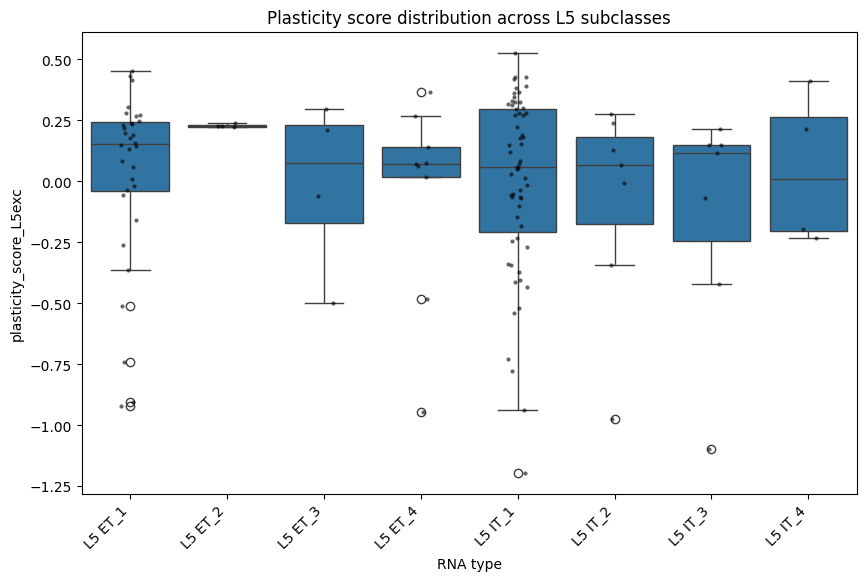

In [20]:
# Attach subclass (RNA type) to plasticity score table
ps = plasticity_score_l5.to_frame(name="plasticity_score_L5exc")
ps["RNA type"] = meta.set_index("Cell").loc[ps.index, "RNA type"]
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.boxplot(
    data=ps,
    x="RNA type",
    y="plasticity_score_L5exc",
    order=sorted(ps["RNA type"].unique())
)
sns.stripplot(
    data=ps,
    x="RNA type",
    y="plasticity_score_L5exc",
    order=sorted(ps["RNA type"].unique()),
    color="black", size=3, alpha=0.6
)
plt.xticks(rotation=45, ha="right")
plt.title("Plasticity score distribution across L5 subclasses")
plt.show()


In [21]:
from scipy.stats import kruskal

groups = [
    ps.loc[ps["RNA type"] == subclass, "plasticity_score_L5exc"].values
    for subclass in sorted(ps["RNA type"].unique())
]

H, p = kruskal(*groups)
print("Kruskal-Wallis H =", H, "p =", p)

Kruskal-Wallis H = 3.82250698409473 p = 0.799979203638123


Mann-Whitney U = 1747.0 p = 0.48667877735907683
t-test t = -0.694552951459683 p = 0.4888331022685347
Cohen's d = -0.1249634608270916


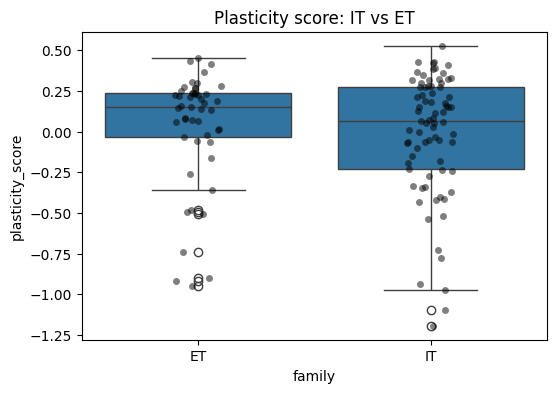

In [22]:
ps = plasticity_score_l5.to_frame(name="plasticity_score")
ps["RNA type"] = meta.set_index("Cell").loc[ps.index, "RNA type"]

ps["family"] = ps["RNA type"].str.contains("IT").map({True: "IT", False: "ET"})
from scipy.stats import mannwhitneyu

it_vals = ps.loc[ps["family"] == "IT", "plasticity_score"]
et_vals = ps.loc[ps["family"] == "ET", "plasticity_score"]

U, p = mannwhitneyu(it_vals, et_vals, alternative="two-sided")
print("Mann-Whitney U =", U, "p =", p)
from scipy.stats import ttest_ind

t, p = ttest_ind(it_vals, et_vals, equal_var=False)
print("t-test t =", t, "p =", p)
import numpy as np

mean_diff = it_vals.mean() - et_vals.mean()
pooled_sd = np.sqrt(((it_vals.var() * (len(it_vals)-1)) +
                     (et_vals.var() * (len(et_vals)-1)))
                     / (len(it_vals)+len(et_vals)-2))

d = mean_diff / pooled_sd
print("Cohen's d =", d)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.boxplot(data=ps, x="family", y="plasticity_score")
sns.stripplot(data=ps, x="family", y="plasticity_score",
              color="black", alpha=0.5)
plt.title("Plasticity score: IT vs ET")
plt.show()


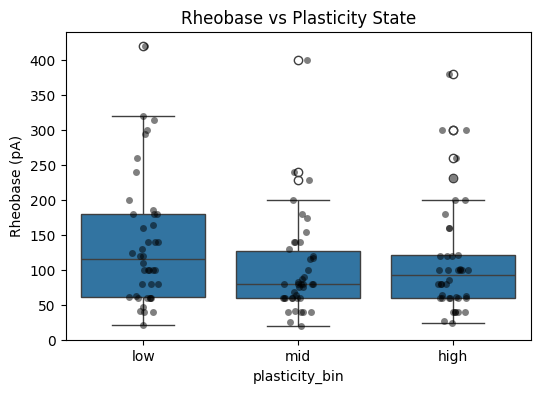

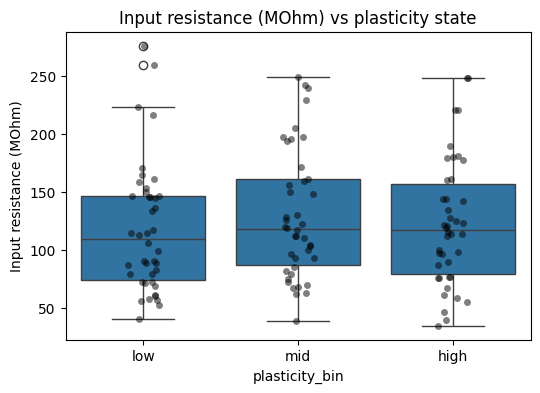

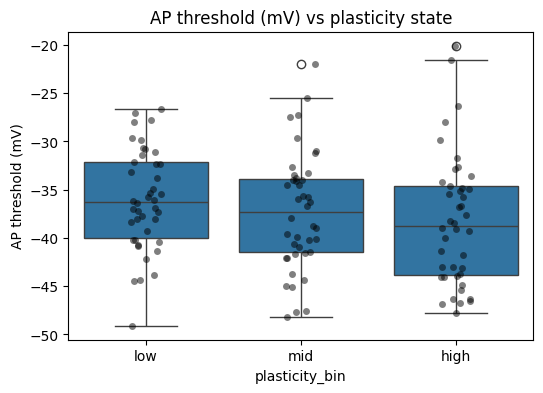

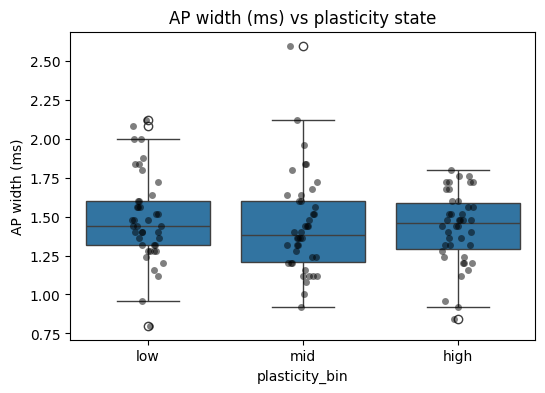

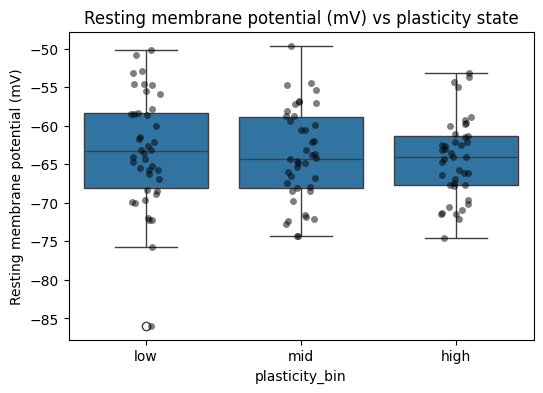

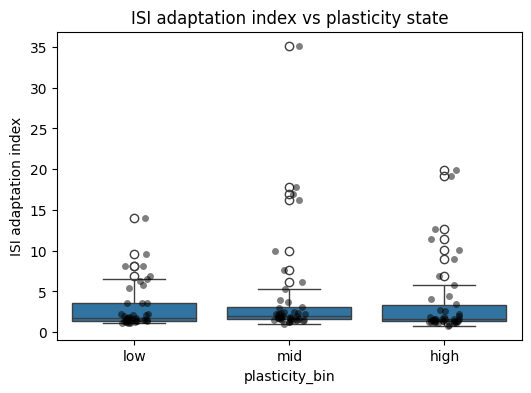

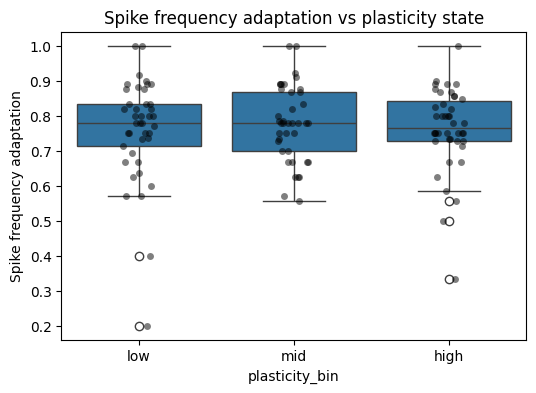

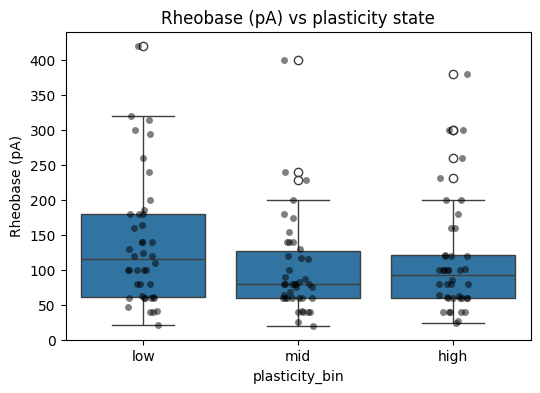

,feature,U,p_value
0,Input resistance (MOhm),825.0,0.613241
1,AP threshold (mV),1094.0,0.058479
2,AP width (ms),953.0,0.527952
3,Resting membrane potential (mV),987.0,0.349859
4,ISI adaptation index,952.0,0.534105
5,Spike frequency adaptation,NaN,NaN
6,Rheobase (pA),1046.5,0.141246


In [23]:
merged_l5["plasticity_bin"] = pd.qcut(
    merged_l5["plasticity_score_L5exc"],
    q=3,
    labels=["low", "mid", "high"]
)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.boxplot(data=merged_l5, x="plasticity_bin", y="Rheobase (pA)")
sns.stripplot(data=merged_l5, x="plasticity_bin", y="Rheobase (pA)",
              color="black", alpha=0.5)
plt.title("Rheobase vs Plasticity State")
plt.show()
for feat in feature_names:
    plt.figure(figsize=(6,4))
    sns.boxplot(data=merged_l5, x="plasticity_bin", y=feat)
    sns.stripplot(data=merged_l5, x="plasticity_bin", y=feat, color="black", alpha=0.5)
    plt.title(f"{feat} vs plasticity state")
    plt.show()
from scipy.stats import mannwhitneyu

results = []
for feat in feature_names:
    low_vals = merged_l5.loc[merged_l5["plasticity_bin"]=="low", feat]
    high_vals = merged_l5.loc[merged_l5["plasticity_bin"]=="high", feat]
    U, p = mannwhitneyu(low_vals, high_vals, alternative="two-sided")
    results.append((feat, U, p))
    
pd.DataFrame(results, columns=["feature", "U", "p_value"])


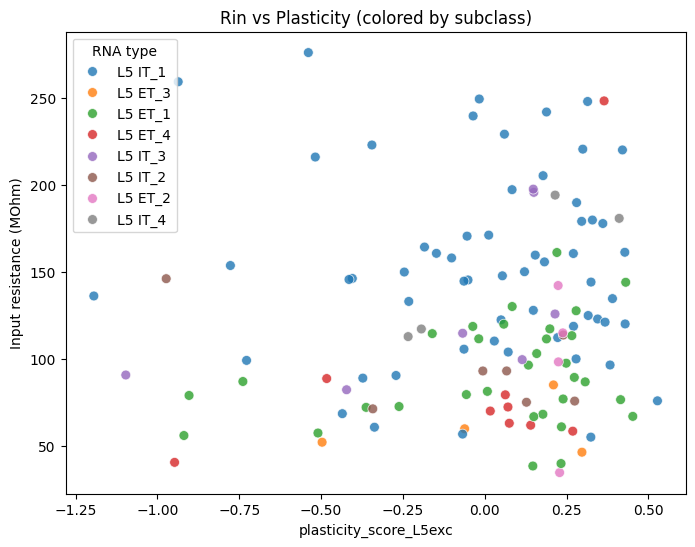

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Map RNA type onto your merged table
merged_l5["RNA type"] = meta.set_index("Cell").loc[
    merged_l5["cell id"], "RNA type"
].values

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=merged_l5,
    x="plasticity_score_L5exc",
    y="Input resistance (MOhm)",
    hue="RNA type",
    palette="tab10",
    s=50,
    alpha=0.8
)
plt.title("Rin vs Plasticity (colored by subclass)")
plt.show()


In [25]:
sub_corrs = []
for subclass in merged_l5["RNA type"].unique():
    sub = merged_l5[merged_l5["RNA type"] == subclass]
    if len(sub) > 10:
        rho, p = spearmanr(sub["plasticity_score_L5exc"], sub["Rheobase (pA)"])
        sub_corrs.append((subclass, rho, p, len(sub)))

pd.DataFrame(sub_corrs, columns=["subclass","rho","p","n"]).sort_values("rho")


,subclass,rho,p,n
1,L5 ET_1,-0.227549,0.210386,32
0,L5 IT_1,-0.038379,0.772892,59


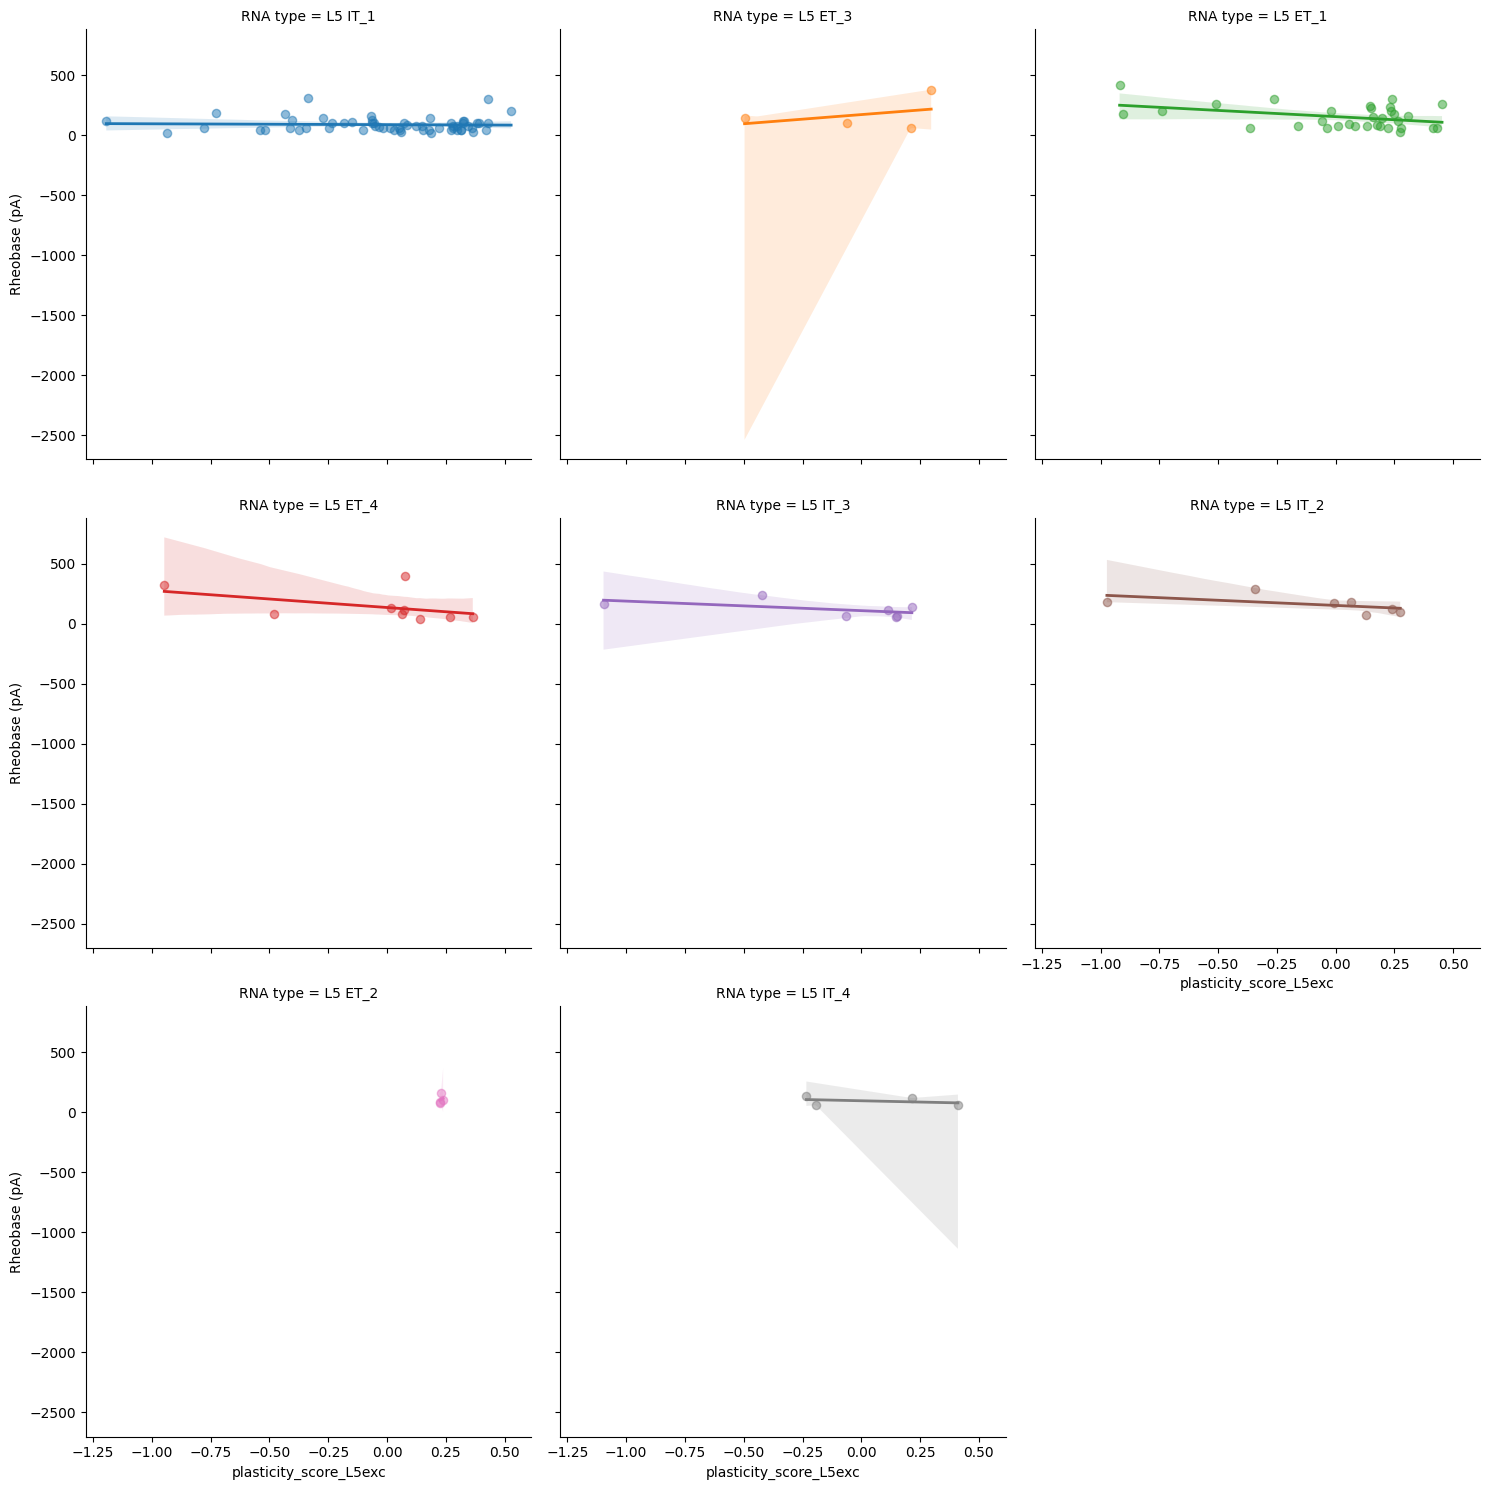

In [26]:
sns.lmplot(
    data=merged_l5,
    x="plasticity_score_L5exc",
    y="Rheobase (pA)",
    hue="RNA type",
    col="RNA type",
    col_wrap=3,
    scatter_kws={'alpha':0.5, 's':35},
    line_kws={'lw':2}
)


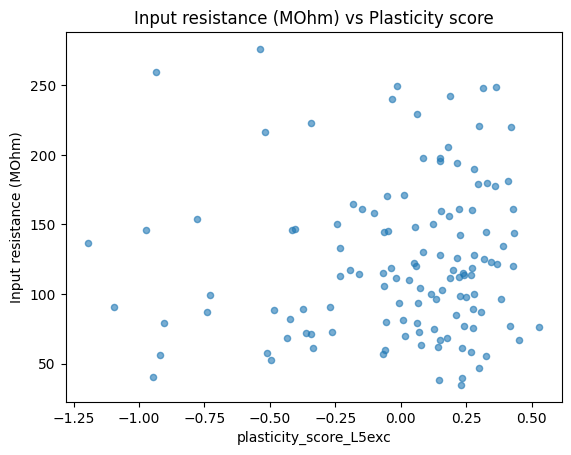

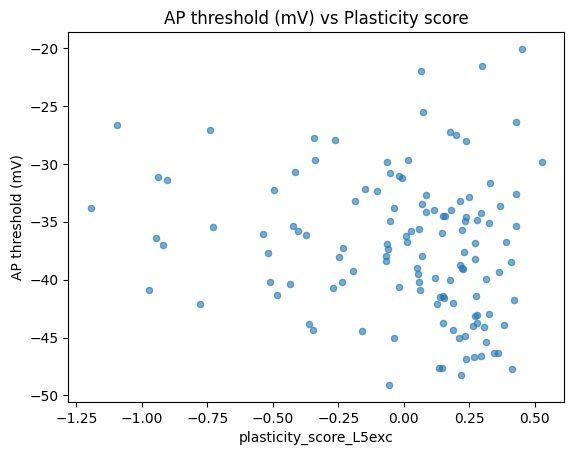

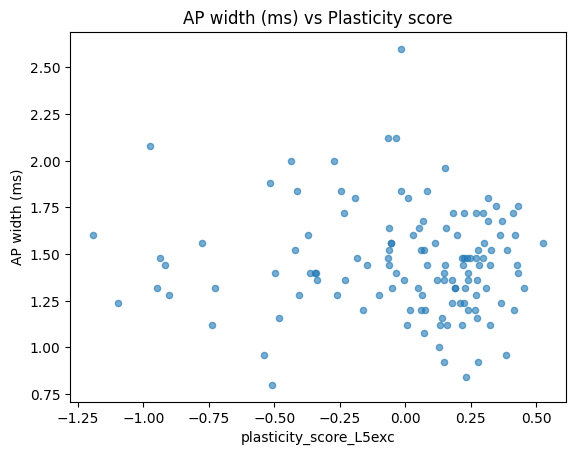

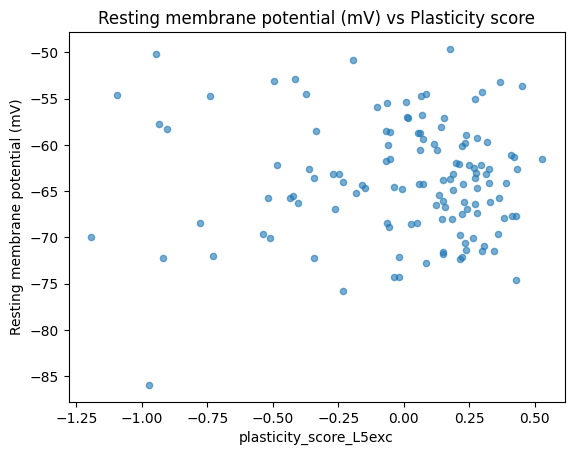

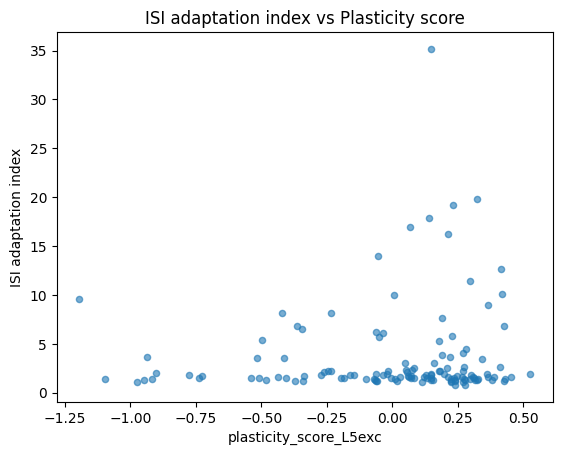

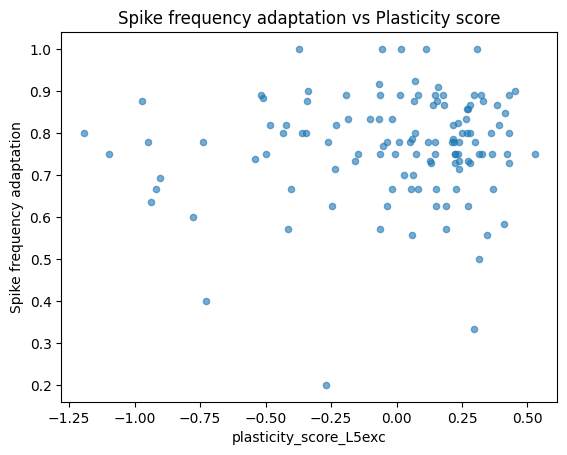

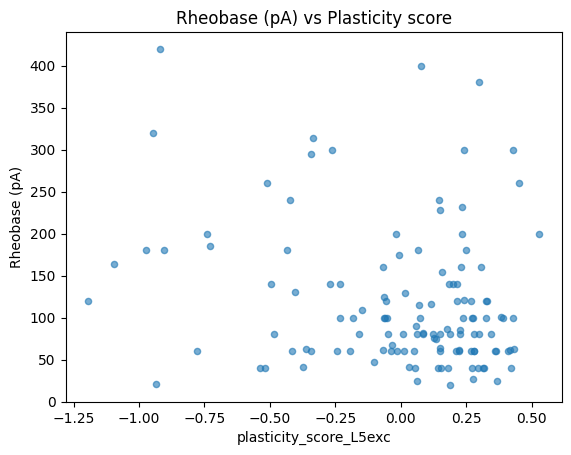

In [27]:
import matplotlib.pyplot as plt

for f in feature_names:
    ax = merged_l5.plot.scatter(x="plasticity_score_L5exc", y=f, alpha=0.6)
    ax.set_title(f"{f} vs Plasticity score")
    plt.show()


/mnt/cf28d361-d831-452b-ac27-06bb7bb8fb9e/SSD_Drive/NeuroData_Discovery_Project/ndd/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


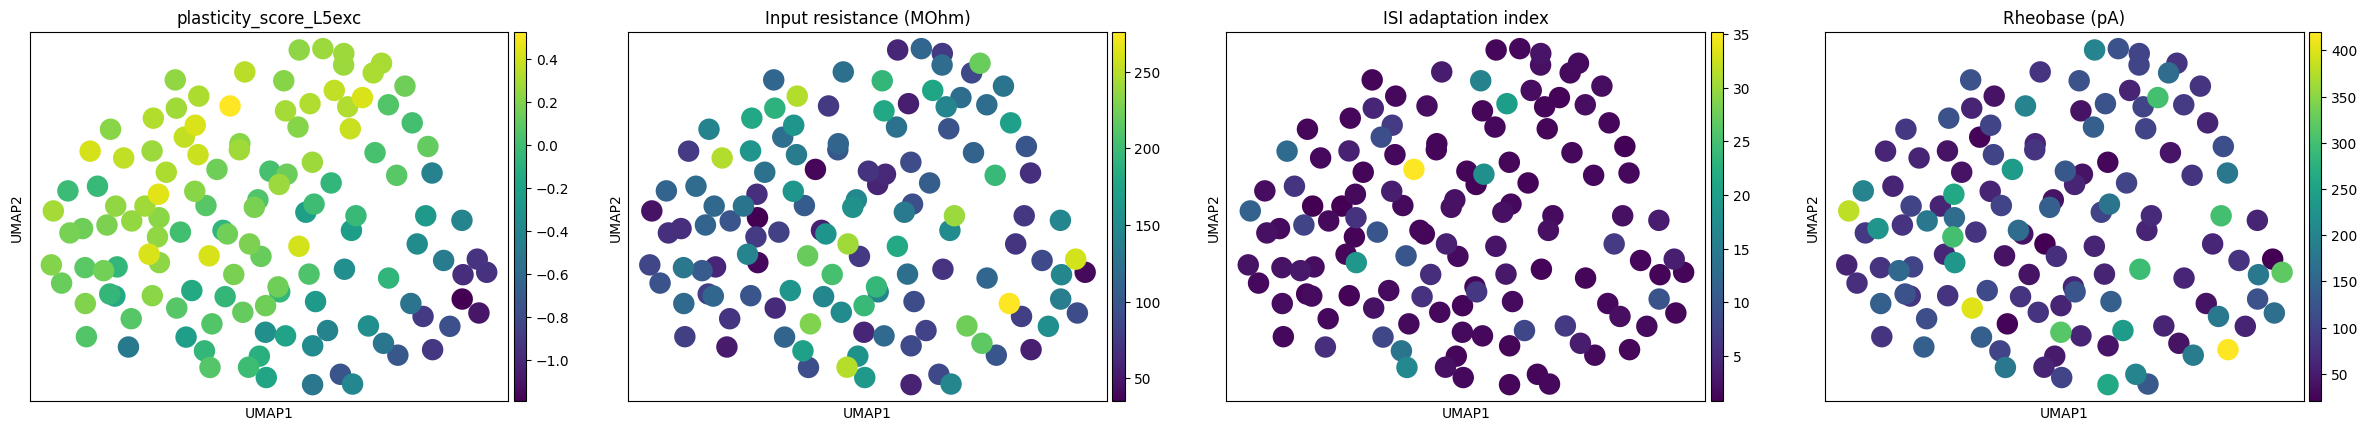

In [30]:
import scanpy as sc

# Use the same ID field as before
id_col = "cell id"

# Make sure order of cells matches between log_cpm and merged
common_ids = log_cpm.index.intersection(merged_l5[id_col])
adata = sc.AnnData(X=log_cpm.loc[common_ids])
adata.obs = merged_l5.set_index(id_col).loc[common_ids]

# Scale & compute embeddings
sc.pp.scale(adata)
sc.pp.pca(adata)
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata)

# Plot colored by features present in adata.obs
sc.pl.umap(adata, color=[
    "plasticity_score_L5exc",
    "Input resistance (MOhm)",
    "ISI adaptation index",
    "Rheobase (pA)"
])


In [33]:
import squidpy as sq

# Squidpy works directly on your existing neighbor graph
sq.gr.spatial_neighbors(adata)   # builds a neighbor graph if not already present

# Compute Moran’s I for any feature
sq.gr.spatial_autocorr(adata, mode="moran", genes=["plasticity_score"])
print(adata.uns["moranI"]["plasticity_score_L5exc"])



KeyError: 'Spatial basis `spatial` not found in `adata.obsm`.'

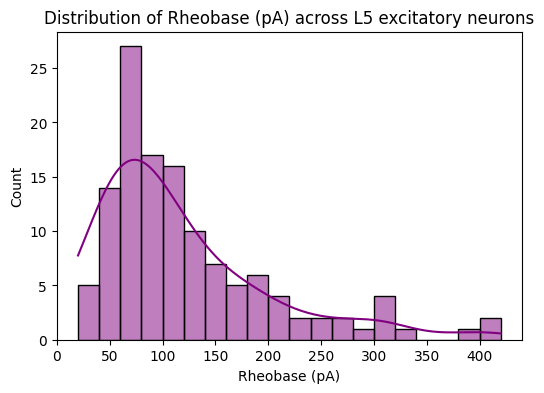

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.histplot(data=merged_l5, x="Rheobase (pA)", bins=20, kde=True, color="purple")
plt.title("Distribution of Rheobase (pA) across L5 excitatory neurons")
plt.xlabel("Rheobase (pA)")
plt.ylabel("Count")
plt.show()


In [35]:
# Align expression with merged_l5 rheobase values
cells = merged_l5["cell id"]

expr_l5 = log_cpm.loc[cells]    # cells × genes
rheobase = merged_l5["Rheobase (pA)"].values


In [36]:
from scipy.stats import spearmanr
import numpy as np
import pandas as pd

gene_names = expr_l5.columns
rho_vals = []
p_vals = []

for g in gene_names:
    r, p = spearmanr(expr_l5[g], rheobase)
    rho_vals.append(r)
    p_vals.append(p)

gene_corr = pd.DataFrame({
    "gene": gene_names,
    "rho": rho_vals,
    "p_value": p_vals
})

# Remove NaNs
gene_corr = gene_corr.dropna()


/tmp/ipykernel_22958/2266803302.py:10: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = spearmanr(expr_l5[g], rheobase)


In [37]:
gene_corr_sorted = gene_corr.sort_values("rho", ascending=False)
gene_corr_sorted.head(20)


,gene,rho,p_value
20156,Gm41804,0.350634,0.000057
41408,Vwc2,0.346761,0.000070
42293,Znrf4,0.322758,0.000228
7375,ERCC-00039,0.312873,0.000361
22312,Gm47273,0.304830,0.000519
10992,Gm13303,0.302884,0.000566
18331,Gm32742,0.302222,0.000583
29885,Lin28b,0.301679,0.000597
7282,Dyrk4,0.293665,0.000846
18069,Gm31300,0.285951,0.001171


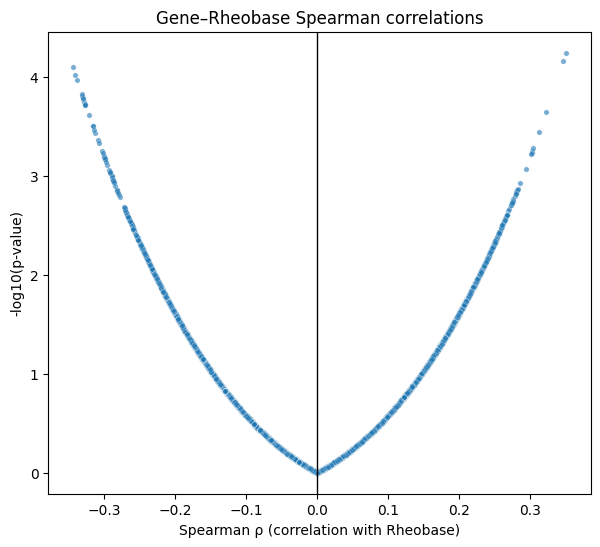

In [38]:
plt.figure(figsize=(7,6))
sns.scatterplot(
    data=gene_corr,
    x="rho",
    y=-np.log10(gene_corr["p_value"]),
    s=15,
    alpha=0.6
)
plt.axvline(0.0, color="black", lw=1)
plt.title("Gene–Rheobase Spearman correlations")
plt.xlabel("Spearman ρ (correlation with Rheobase)")
plt.ylabel("-log10(p-value)")
plt.show()


In [39]:
top_neg = gene_corr.sort_values("rho").head(30)
top_neg


,gene,rho,p_value
29133,Jun,-0.344192,0.000079
5208,Cdk14,-0.340586,0.000095
1853,9130024F11Rik,-0.338163,0.000108
39791,Tob1,-0.331606,0.000149
29943,Lmo4,-0.330884,0.000154
37982,Smyd3,-0.329802,0.000162
35685,Rasl11b,-0.329400,0.000166
3750,Atp8a1,-0.327911,0.000178
29860,Lhx2,-0.326853,0.000187
39822,Topors,-0.326509,0.000190


In [40]:
top_pos = gene_corr.sort_values("rho", ascending=False).head(30)
top_pos


,gene,rho,p_value
20156,Gm41804,0.350634,0.000057
41408,Vwc2,0.346761,0.000070
42293,Znrf4,0.322758,0.000228
7375,ERCC-00039,0.312873,0.000361
22312,Gm47273,0.304830,0.000519
10992,Gm13303,0.302884,0.000566
18331,Gm32742,0.302222,0.000583
29885,Lin28b,0.301679,0.000597
7282,Dyrk4,0.293665,0.000846
18069,Gm31300,0.285951,0.001171


In [41]:
genes_of_interest = [
    "FOS","FOSB","FOSL1","FOSL2","JUN","JUNB","JUND","EGR1","EGR2","EGR3","EGR4",
    "NPAS4","KLF2","KLF4","KLF6","KLF9","KLF10","KLF11","ATF3","ATF4","ATF5","ATF7",
    "CREM","CREB1","CREB3","CREB5","SRF","ELK1","ELK3","ELK4","NR4A1","NR4A2","NR4A3",
    "BTG1","BTG2","IER2","IER3","IER5","ARC","HOMER1","BDNF","NPTX2","NPTX1","NPTXR",
    "SYT4","CAMK2G","CAMK1G","CAMK4","MAPK8IP2","MAPK1IP1L",
    "RGS2","RGS4","RGS14","DUSP1","DUSP4","DUSP5","DUSP6",
    "PPP1R1B","PPP1R15A","PLK2","PLK3","PRKCZ","PRKCI","RAPGEF4","RAPGEF5","RAPGEF3",
    "GADD45A","GADD45B","GADD45G","DNMT3A","DNMT3B","MECP2","HDAC4","HDAC5","HDAC9",
    "RCAN1","RCAN2","RCAN3","CALN1","CALM1","CALM2","CALM3",
    "CAMKK1","CAMKK2","AKAP5","AKAP6","AKAP11","AKAP12","AKAP13",
    "HSPB1","HSPA1A","HSPA1B","DDIT3","CHAC1","TRIB1","TRIB2","TRIB3",
    "SGK1","SGK3","SERTAD1","SERTAD2","SERTAD3",
    "BAIAP2","BAIAP3","SIPA1L1","SIPA1L2","SYNPO","SYNPO2","SYNGAP1",
    "DLG4","DLG3","SHANK1","SHANK2","SHANK3",
    "RHOA","RHOB","RHOC","RHOU","RND1","RND2","RND3",
    "MAPK8","MAPK10","MAPT","RASGRF1","RASGRF2","RAP1GAP","RAP1GDS1",
    "PAK1","PAK3"
]

genes_of_interest =  [g[0]+ g[1:].lower() for g in genes_of_interest]
plasticity_genes = [g for g in genes_of_interest if g in log_cpm_l5.columns]

expr_plastic = log_cpm_l5[plasticity_genes]

results = []
for g in plasticity_genes:
    rho, p = spearmanr(expr_plastic[g], merged_l5["Rheobase (pA)"])
    results.append((g, rho, p))

pd.DataFrame(results, columns=["gene","rho","p"]).sort_values("rho")


,gene,rho,p
67,Gadd45g,-0.323732,0.000218
7,Egr1,-0.296729,0.000741
96,Sgk1,-0.268760,0.002343
116,Rnd1,-0.262294,0.003007
34,Ier2,-0.261904,0.003052
...,...,...,...
101,Baiap2,0.056494,0.529791
79,Calm2,0.067374,0.453507
75,Rcan2,0.088376,0.325085
36,Ier5,0.088451,0.324674


In [42]:
import pandas as pd
from scipy.stats import spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

genes_of_interest = [
    "FOS","FOSB","FOSL1","FOSL2","JUN","JUNB","JUND","EGR1","EGR2","EGR3","EGR4",
    "NPAS4","KLF2","KLF4","KLF6","KLF9","KLF10","KLF11","ATF3","ATF4","ATF5","ATF7",
    "CREM","CREB1","CREB3","CREB5","SRF","ELK1","ELK3","ELK4","NR4A1","NR4A2","NR4A3",
    "BTG1","BTG2","IER2","IER3","IER5","ARC","HOMER1","BDNF","NPTX2","NPTX1","NPTXR",
    "SYT4","CAMK2G","CAMK1G","CAMK4","MAPK8IP2","MAPK1IP1L",
    "RGS2","RGS4","RGS14","DUSP1","DUSP4","DUSP5","DUSP6",
    "PPP1R1B","PPP1R15A","PLK2","PLK3","PRKCZ","PRKCI","RAPGEF4","RAPGEF5","RAPGEF3",
    "GADD45A","GADD45B","GADD45G","DNMT3A","DNMT3B","MECP2","HDAC4","HDAC5","HDAC9",
    "RCAN1","RCAN2","RCAN3","CALN1","CALM1","CALM2","CALM3",
    "CAMKK1","CAMKK2","AKAP5","AKAP6","AKAP11","AKAP12","AKAP13",
    "HSPB1","HSPA1A","HSPA1B","DDIT3","CHAC1","TRIB1","TRIB2","TRIB3",
    "SGK1","SGK3","SERTAD1","SERTAD2","SERTAD3",
    "BAIAP2","BAIAP3","SIPA1L1","SIPA1L2","SYNPO","SYNPO2","SYNGAP1",
    "DLG4","DLG3","SHANK1","SHANK2","SHANK3",
    "RHOA","RHOB","RHOC","RHOU","RND1","RND2","RND3",
    "MAPK8","MAPK10","MAPT","RASGRF1","RASGRF2","RAP1GAP","RAP1GDS1",
    "PAK1","PAK3"
]

genes_of_interest =  [g[0]+ g[1:].lower() for g in genes_of_interest]
plasticity_genes = [g for g in genes_of_interest if g in log_cpm_l5.columns]
expr_plastic = log_cpm_l5[plasticity_genes]

ephys_features = [
    "Input resistance (MOhm)",
    "AP threshold (mV)",
    "AP width (ms)",
    "Resting membrane potential (mV)",
    "ISI adaptation index",
    "Spike frequency adaptation",
    "Rheobase (pA)",
]

# 1) Build a single table with ephys + plasticity genes, keyed by cell id
df = merged_l5[["cell id"] + ephys_features].copy()

df = df.merge(
    expr_plastic,
    left_on="cell id",
    right_index=True,
    how="inner",
)

print("Merged ephys+RNA shape:", df.shape)

# 2) Compute correlations gene × feature
results = []
for gene in plasticity_genes:
    for feat in ephys_features:
        if feat not in df.columns:
            continue
        s = df[[gene, feat]].dropna()
        if len(s) > 3:
            rho, p = spearmanr(s[gene], s[feat])
            results.append((gene, feat, rho, p))

corr_table = pd.DataFrame(results, columns=["gene","feature","rho","p"])
print("corr_table shape:", corr_table.shape)
print(corr_table.head())


Merged ephys+RNA shape: (126, 136)
corr_table shape: (896, 4)
  gene                          feature       rho         p
0  Fos          Input resistance (MOhm)  0.078848  0.380157
1  Fos                AP threshold (mV) -0.111664  0.213192
2  Fos                    AP width (ms) -0.000189  0.998323
3  Fos  Resting membrane potential (mV) -0.147169  0.100079
4  Fos             ISI adaptation index  0.018157  0.840073


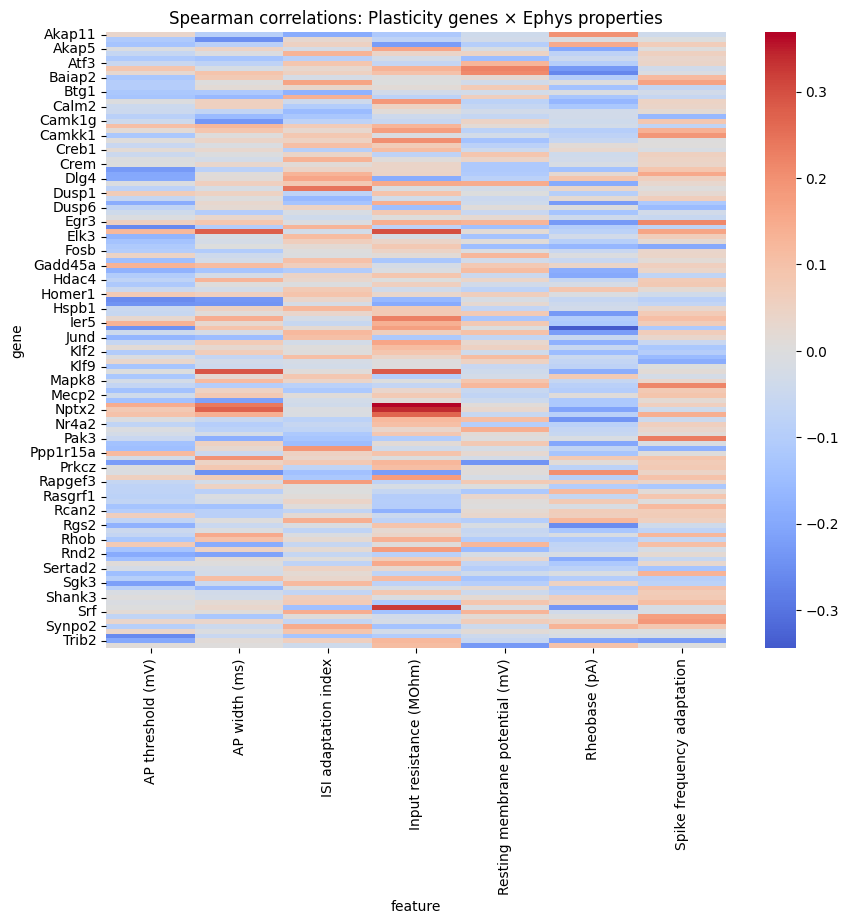

In [49]:
heat = corr_table.pivot(index="gene", columns="feature", values="rho")

plt.figure(figsize=(10,8))
sns.heatmap(heat, cmap="coolwarm", center=0, annot=False)
plt.title("Spearman correlations: Plasticity genes × Ephys properties")
plt.show()

# p-values in matching layout if you want them
heat_p = corr_table.pivot(index="gene", columns="feature", values="p")


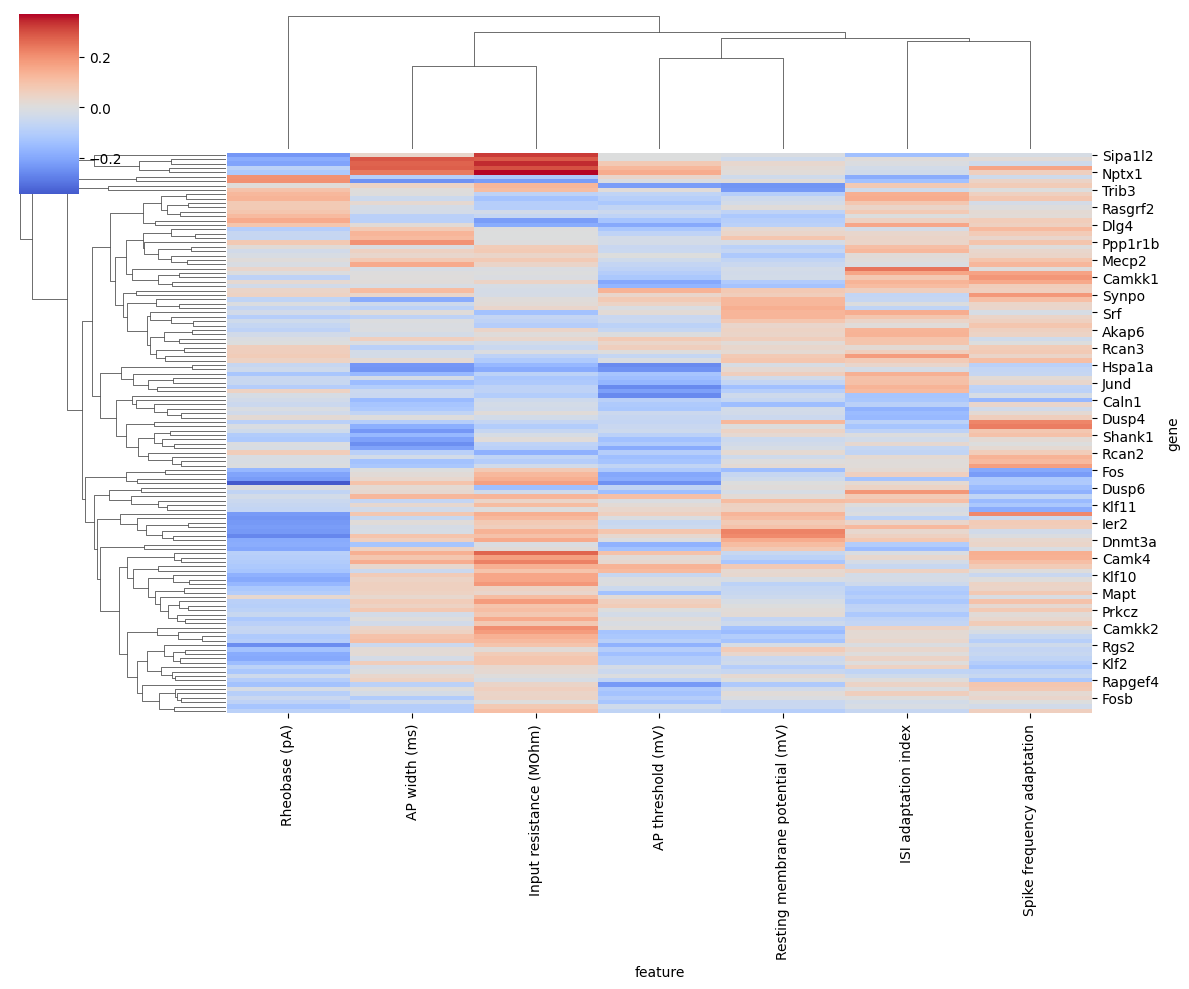

In [44]:
sns.clustermap(heat, cmap="coolwarm", center=0, figsize=(12,10))


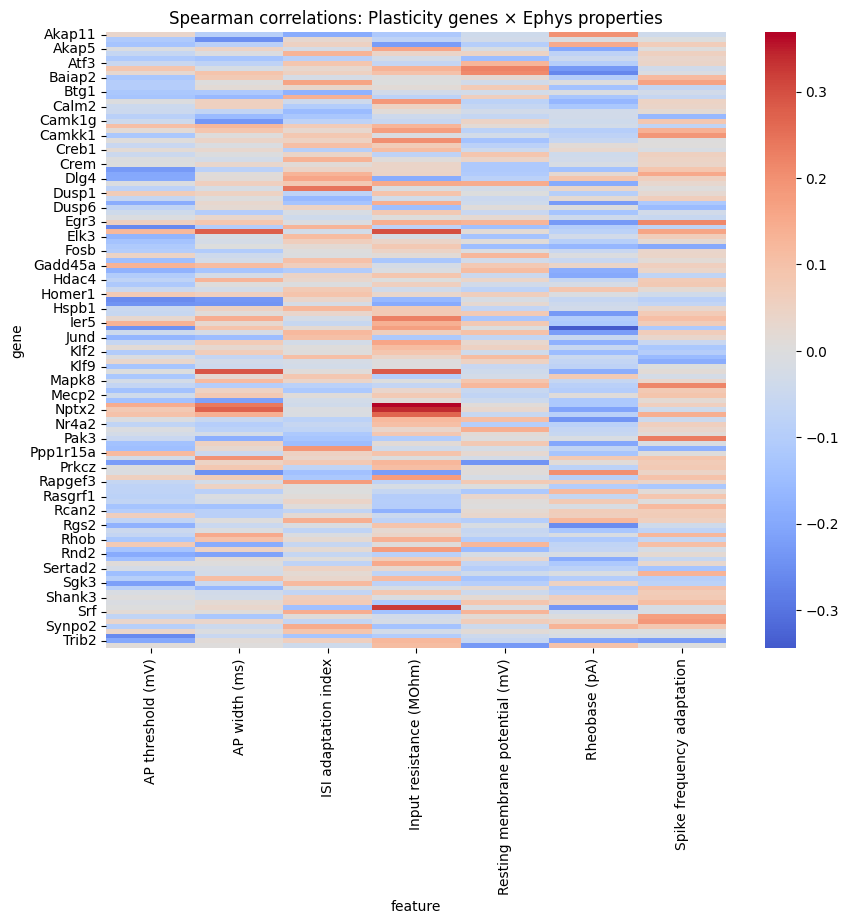

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(heat, cmap="coolwarm", center=0, annot=False)
plt.title("Spearman correlations: Plasticity genes × Ephys properties")
plt.show()

heat_p = corr_table.pivot(index="gene", columns="feature", values="p")

In [52]:
import gseapy as gp

ranks = gene_corr.set_index("gene")["rho"]
ranks = ranks.sort_values(ascending=False)

gp.prerank(
    rnk=ranks,
    gene_sets='GO_Biological_Process',
    outdir='gsea_rheobase'
)


2025-12-13 17:48:53,745 [WARNING] Duplicated values found in preranked stats: 20.94% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-12-13 17:49:27,113 [ERROR] No supported gene_sets: GO_Biological_Process


Exception: Error parsing gmt parameter for gene sets

In [16]:
import pandas as pd
import numpy as np
import re

# 0) Load the metadata (it’s usually tab-delimited in the Allen dump)
meta_path = "PatchSeqExpression/m1_patchseq_meta_data.csv"
meta = pd.read_csv(meta_path, sep=None, engine="python")  # auto-detects comma/tab

print("meta cols:", list(meta.columns)[:15])

# 1) Pick an ID column in meta that best matches your ephys IDs ("cell id")
id_col_ephys = "cell id"
merged[id_col_ephys] = merged[id_col_ephys].astype(str).str.strip()

# Try several likely ID columns from meta & choose the one with max overlap
id_candidates = [c for c in meta.columns
                 if re.search(r'cell|id|specimen|patch', c, flags=re.I)]

def best_id_column(meta, target_ids):
    target_ids = set(target_ids.astype(str))
    best = None
    best_n = -1
    for c in id_candidates:
        s = meta[c].astype(str).str.strip()
        n = len(set(s) & target_ids)
        if n > best_n:
            best, best_n = c, n
    return best, best_n

best_col, n_match = best_id_column(meta, merged[id_col_ephys])
print(f"Best meta ID col: {best_col} (intersect={n_match})")

# 2) Normalize and merge
meta_best = meta.copy()
meta_best[best_col] = meta_best[best_col].astype(str).str.strip()

merged2 = merged.merge(
    meta_best.set_index(best_col),
    left_on=id_col_ephys,
    right_index=True,
    how="left"
)

# Inspect which columns look like layer annotations
layer_cols = [c for c in merged2.columns if re.search(r'layer', c, flags=re.I)]
print("Candidate layer columns:", layer_cols)


meta cols: ['Number', 'Cell', 'Slice', 'Date', 'Sample', 'Mouse', 'Mouse date of birth', 'Mouse age', 'Mouse gender', 'Mouse genotype', 'Targeted layer', 'Inferred layer', 'Cre', 'Exon reads', 'Intron reads']
Best meta ID col: Cell (intersect=1328)
Candidate layer columns: ['Targeted layer', 'Inferred layer']


In [50]:
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

print("Layer-5 cells:", len(merged_l5))

feature_names = [
    "Input resistance (MOhm)",
    "AP threshold (mV)",
    "AP width (ms)",
    "Resting membrane potential (mV)",
    "ISI adaptation index",
    "Spike frequency adaptation",
    "Rheobase (pA)",
]

rows = []
for f in feature_names:
    if f in merged_l5.columns:
        s = merged_l5[[f, "plasticity_score_L5exc"]].dropna()
        if len(s) > 2:
            rho, p = spearmanr(s["plasticity_score_L5exc"], s[f])
            rows.append((f, rho, p, len(s)))

summary_L5 = pd.DataFrame(rows, columns=["feature","spearman_rho","p_value","n"])
summary_L5["p_fdr"] = multipletests(summary_L5["p_value"], method="fdr_bh")[1]
summary_L5 = summary_L5.sort_values("spearman_rho", ascending=False)
summary_L5


Layer-5 cells: 126


,feature,spearman_rho,p_value,n,p_fdr
0,Input resistance (MOhm),0.126497,0.158111,126,0.441314
2,AP width (ms),-0.024327,0.786864,126,0.786864
5,Spike frequency adaptation,-0.024633,0.786819,123,0.786864
4,ISI adaptation index,-0.024720,0.783503,126,0.786864
3,Resting membrane potential (mV),-0.037066,0.680293,126,0.786864
1,AP threshold (mV),-0.117750,0.189134,126,0.441314
6,Rheobase (pA),-0.217884,0.014251,126,0.099754


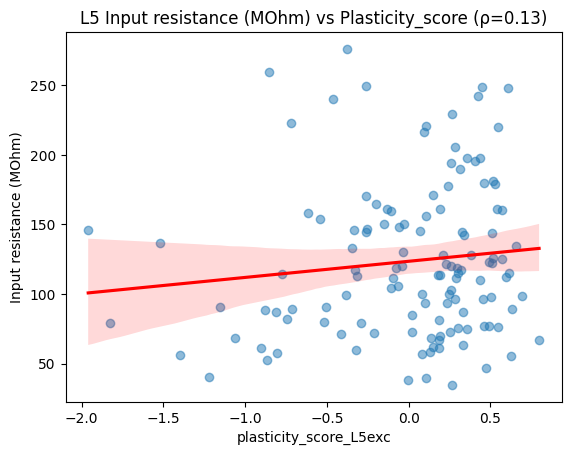

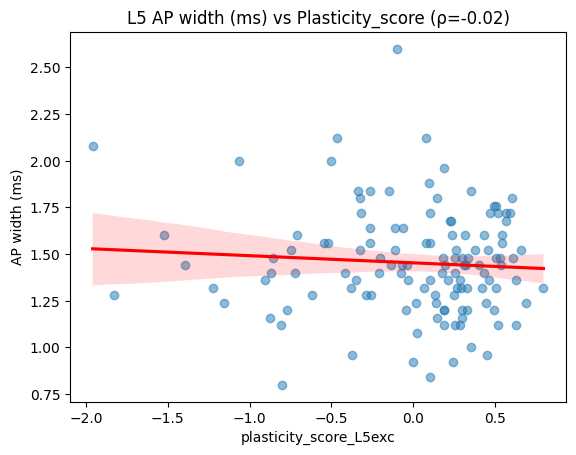

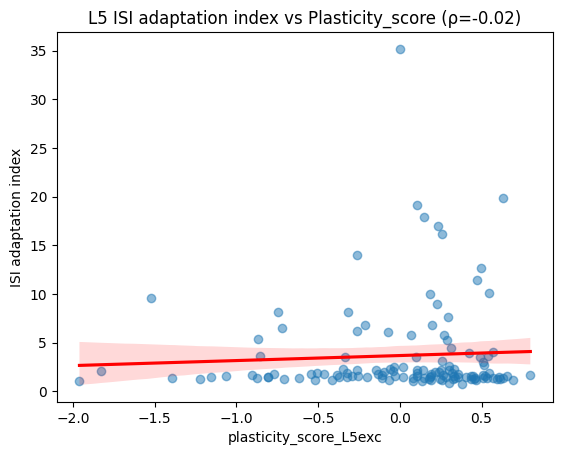

In [51]:
import seaborn as sns, matplotlib.pyplot as plt
for f in ["Input resistance (MOhm)", "AP width (ms)", "ISI adaptation index"]:
    sns.regplot(data=merged_l5, x="plasticity_score_L5exc", y=f, scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
    plt.title(f"L5 {f} vs Plasticity_score (ρ={summary_L5.loc[summary_L5.feature==f,'spearman_rho'].values[0]:.2f})")
    plt.show()


<Axes: ylabel='feature'>

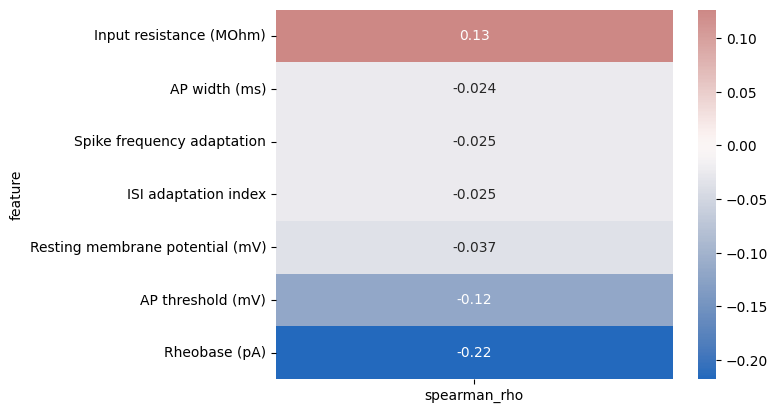

In [52]:
sns.heatmap(summary_L5.set_index("feature")[["spearman_rho"]], annot=True, cmap="vlag", center=0)


In [22]:
# confirm what's actually in adata.obs
print(adata.obs.columns[:20])


Index(['AP Fano factor', 'AP amplitude (mV)', 'AP amplitude adaptation index',
       'AP amplitude average adaptation index', 'AP coefficient of variation',
       'AP threshold (mV)', 'AP width (ms)', 'Afterdepolarization (mV)',
       'Afterhyperpolarization (mV)', 'Burstiness', 'ISI Fano factor',
       'ISI adaptation index', 'ISI average adaptation index',
       'ISI coefficient of variation', 'Input resistance (MOhm)',
       'Latency (ms)', 'Latency @ +20pA current (ms)', 'Max number of APs',
       'Membrane time constant (ms)', 'Rebound (mV)'],
      dtype='object')


In [23]:

meta = pd.read_csv("PatchSeqExpression/m1_patchseq_meta_data.csv", sep="\t")
meta = meta.rename(columns={"Cell":"cell id"}).set_index("cell id")

# add layer labels to adata.obs
adata.obs = adata.obs.join(meta[["Targeted layer","Inferred layer"]], how="left")

print([c for c in adata.obs.columns if "layer" in c.lower()])


['Targeted layer', 'Inferred layer']


In [26]:
import numpy as np
import scanpy as sc

# 0) Make the L5 subset from your existing `adata`
adata_l5 = adata[adata.obs["Targeted layer"].astype(str).str.contains("5", na=False)].copy()

# 1) Remove genes/cells with no counts in this subset
sc.pp.filter_genes(adata_l5, min_counts=1)   # drop all-zeros genes
sc.pp.filter_cells(adata_l5, min_counts=1)   # (usually none, but safe)

# 2) Keep highly variable genes only (stabilizes scaling/PCA)
sc.pp.highly_variable_genes(adata_l5, flavor="seurat_v3", n_top_genes=2000)
adata_l5 = adata_l5[:, adata_l5.var["highly_variable"]].copy()

# 3) (Extra guard) drop zero-variance genes that slipped through
#    Works for both dense and sparse matrices
X = adata_l5.X.A if hasattr(adata_l5.X, "A") else adata_l5.X
std = np.asarray(X).std(axis=0)
keep = std > 0
adata_l5 = adata_l5[:, keep].copy()

# 4) Scale safely (clip extreme z-scores)
sc.pp.scale(adata_l5, zero_center=True, max_value=10)

# 5) PCA/Neighbors/UMAP
sc.pp.pca(adata_l5)
sc.pp.neighbors(adata_l5, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_l5)

sc.pl.umap(adata_l5, color=[
    "plasticity_score",
    "Input resistance (MOhm)",
    "AP width (ms)",
    "ISI adaptation index",
    "Rheobase (pA)"
])


/home/peter/.local/lib/python3.10/site-packages/legacy_api_wrap/__init__.py:82: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)
/home/peter/.local/lib/python3.10/site-packages/scanpy/preprocessing/_highly_variable_genes.py:101: RuntimeWarning: invalid value encountered in log10
  x = np.log10(mean[not_const])


ValueError: b'Extrapolation not allowed with blending'

In [25]:
import pingouin as pg
pg.partial_corr(data=merged_l5,
                x="plasticity_score",
                y="Input resistance (MOhm)",
                covar=["Rheobase (pA)","AP width (ms)"],
                method="spearman")


,n,r,CI95%,p-val
spearman,576,-0.343227,"[-0.41, -0.27]",2.591338e-17


In [27]:
import statsmodels.api as sm
X = merged_l5[["Input resistance (MOhm)","AP width (ms)","ISI adaptation index","Rheobase (pA)"]]
X = sm.add_constant(X)
y = merged_l5["plasticity_score"]
model = sm.OLS(y, X, missing="drop").fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:       plasticity_score   R-squared:                       0.197
Model:                            OLS   Adj. R-squared:                  0.191
Method:                 Least Squares   F-statistic:                     34.98
Date:                Sat, 08 Nov 2025   Prob (F-statistic):           3.84e-26
Time:                        22:46:23   Log-Likelihood:                -402.81
No. Observations:                 575   AIC:                             815.6
Df Residuals:                     570   BIC:                             837.4
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                   -2

In [28]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
Xz = scaler.fit_transform(merged_l5[["Input resistance (MOhm)",
                                     "AP width (ms)",
                                     "ISI adaptation index",
                                     "Rheobase (pA)"]])
Xz = sm.add_constant(Xz)
model_z = sm.OLS(y, Xz, missing="drop").fit()
print(model_z.summary())


                            OLS Regression Results                            
Dep. Variable:       plasticity_score   R-squared:                       0.197
Model:                            OLS   Adj. R-squared:                  0.191
Method:                 Least Squares   F-statistic:                     34.98
Date:                Sat, 08 Nov 2025   Prob (F-statistic):           3.84e-26
Time:                        22:48:54   Log-Likelihood:                -402.81
No. Observations:                 575   AIC:                             815.6
Df Residuals:                     570   BIC:                             837.4
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0012      0.020      0.058      0.9

In [29]:
import statsmodels.api as sm

predictors = ["plasticity_score"]
targets = ["Input resistance (MOhm)", "AP width (ms)",
            "ISI adaptation index", "Rheobase (pA)"]

out = []
for f in targets:
    X = sm.add_constant(merged_l5[predictors])
    y = merged_l5[f]
    model = sm.OLS(y, X, missing="drop").fit()
    out.append({
        "feature": f,
        "slope": model.params["plasticity_score"],
        "t": model.tvalues["plasticity_score"],
        "p": model.pvalues["plasticity_score"],
        "R2": model.rsquared
    })

pd.DataFrame(out).sort_values("R2", ascending=False)


,feature,slope,t,p,R2
0,Input resistance (MOhm),-55.313459,-7.878655,1.667468e-14,0.097588
1,AP width (ms),0.229327,7.844096,2.139178e-14,0.096817
2,ISI adaptation index,0.866729,4.228945,2.732712e-05,0.030266
3,Rheobase (pA),14.868669,2.918601,3.653868e-03,0.014623


In [30]:
from sklearn.cross_decomposition import PLSRegression
X = merged_l5[["plasticity_score"]].values
Y = merged_l5[["Input resistance (MOhm)",
               "AP width (ms)",
               "ISI adaptation index",
               "Rheobase (pA)"]].values

pls = PLSRegression(n_components=1)
pls.fit(X, Y)
print("Explained variance in Y:", pls.score(X, Y))


ValueError: Input Y contains NaN.

In [ ]:
import statsmodels.api as sm
X = merged_l5[["Input resistance (MOhm)","AP width (ms)","ISI adaptation index","Rheobase (pA)"]]
X = sm.add_constant(X)
y = merged_l5["plasticity_score"]
model = sm.OLS(y, X, missing="drop").fit()
print(model.summary())


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

for f in feature_names:
    if f in merged_l5.columns:
        sns.regplot(data=merged_l5, x="plasticity_score", y=f, scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
        plt.title(f"L5: {f} vs Plasticity_score")
        plt.show()


In [ ]:
import statsmodels.api as sm

coords = adata.obsm['X_umap']
df = pd.DataFrame(coords, columns=['UMAP1','UMAP2'], index=adata.obs_names)
df['plasticity_score'] = adata.obs['plasticity_score']

model = sm.OLS(df['plasticity_score'], sm.add_constant(df[['UMAP1','UMAP2']])).fit()
print(model.summary())


In [ ]:
for f in ["Input resistance (MOhm)", "Rheobase (pA)", "ISI adaptation index"]:
    sc.tl.moran(adata, f)
    print(f, adata.uns['moran']['I'], adata.uns['moran']['pval'])


In [3]:
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import re
from pathlib import Path

COUNTS = Path("PatchSeqExpression/GSE163764_m1_patchseq_exon_counts.csv")
SERIES = Path("PatchSeqExpression/GSE163764_series_matrix.txt")

# counts file: first column = gene symbols, remaining columns = cell IDs like "20180420_sample_2"
counts_gxc = pd.read_csv(COUNTS, index_col=0)          # genes × cells
expr = counts_gxc.T                                   # cells × genes

# make an AnnData from the full matrix (we’ll use this for PCA/UMAP)
adata = ad.AnnData(X=expr.values, obs=pd.DataFrame(index=expr.index),
                   var=pd.DataFrame(index=expr.columns))


Present genes: ['Fos', 'Fosb', 'Junb', 'Egr1', 'Egr2', 'Npas4', 'Arc', 'Nr4a1', 'Nr4a2', 'Bdnf', 'Nptx2', 'Syt4', 'Camk2g', 'Rgs4', 'Dusp1', 'Atf3', 'Crem', 'Gadd45b', 'Gadd45g', 'Prkcz']


/home/peter/.local/lib/python3.10/site-packages/legacy_api_wrap/__init__.py:82: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)
/home/peter/.local/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


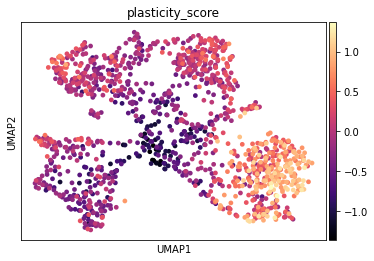

In [4]:
import pandas as pd, numpy as np, scanpy as sc, anndata as ad

COUNTS = "PatchSeqExpression/GSE163764_m1_patchseq_exon_counts.csv"

# 1) Load counts (genes×cells) → cells×genes
counts_gxc = pd.read_csv(COUNTS, index_col=0)
expr = counts_gxc.T  # cells × genes

# 2) AnnData + logCPM layer
adata = ad.AnnData(expr.values, obs=pd.DataFrame(index=expr.index),
                   var=pd.DataFrame(index=expr.columns))
libsize = adata.X.sum(axis=1)
if hasattr(libsize, "A1"): libsize = libsize.A1
cpm = adata.X / libsize[:, None] * 1e6
adata.layers["logcpm"] = np.log1p(cpm)

# 3) Plasticity score (IEG set)
genes_plastic = ["Fos","Fosb","Junb","Egr1","Egr2","Npas4","Arc","Homer1a",
                 "Nr4a1","Nr4a2","Bdnf","Nptx2","Syt4","Camk2g",
                 "Rgs4","Dusp1","Atf3","Crem","Gadd45b","Gadd45g","Prkcz"]
present = [g for g in genes_plastic if g in adata.var_names]
adata_pl = adata[:, present].copy()
X = np.asarray(adata_pl.layers["logcpm"])
Xz = (X - X.mean(axis=0)) / X.std(axis=0)
adata.obs["plasticity_score"] = Xz.mean(axis=1)
print("Present genes:", present)

# 4) Embed ALL CELLS (HVGs from logCPM) and color by plasticity
adata_use = adata.copy()
adata_use.X = adata.layers["logcpm"]
sc.pp.highly_variable_genes(adata_use, n_top_genes=3000, flavor="seurat_v3")
adata_use = adata_use[:, adata_use.var["highly_variable"]].copy()
sc.pp.scale(adata_use, zero_center=False)
sc.tl.pca(adata_use, n_comps=50, svd_solver="auto")
sc.pp.neighbors(adata_use, n_neighbors=15, n_pcs=50)
sc.tl.umap(adata_use)
adata_use.obs["plasticity_score"] = adata.obs["plasticity_score"]

sc.pl.umap(adata_use, color=["plasticity_score"], cmap="magma")

# 5) Save outputs
adata_use.write_h5ad("Outputs/GSE163764_allcells_logcpm_hvg_umap.h5ad", compression="lzf")
adata.obs[["plasticity_score"]].to_csv("Outputs/GSE163764_plasticity_scores.csv")


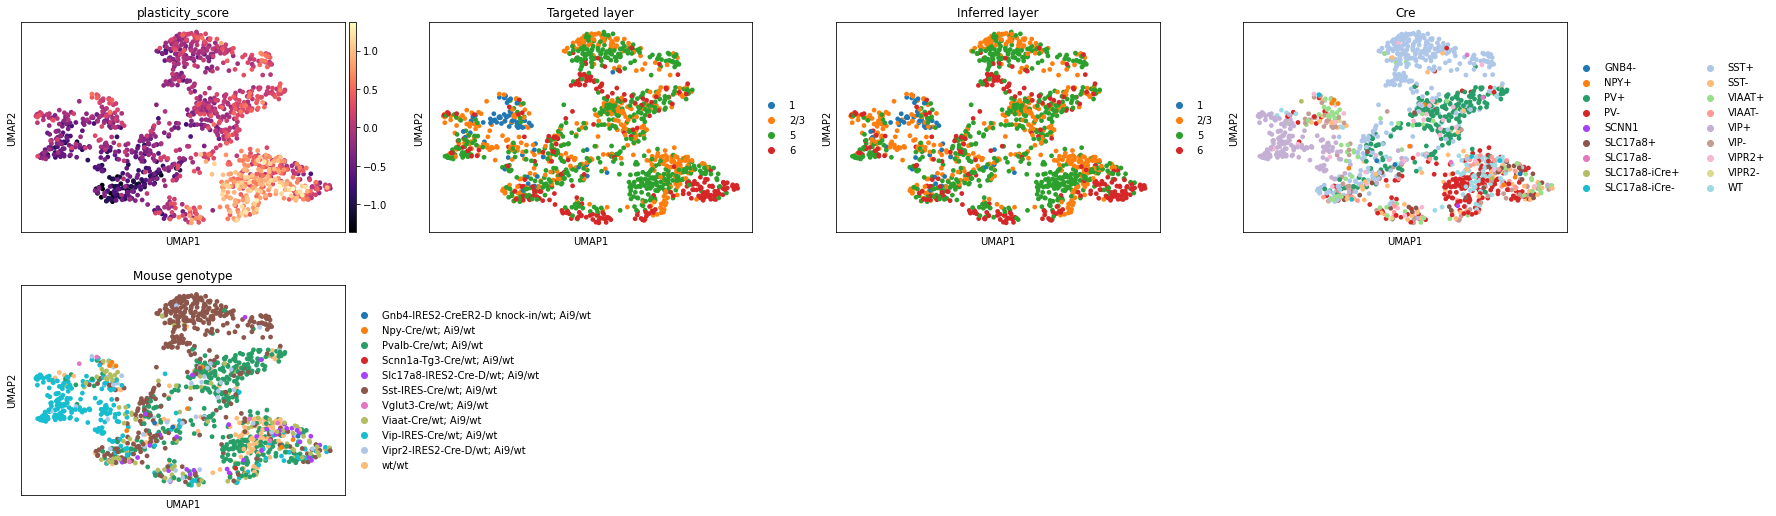

In [5]:
import pandas as pd
import scanpy as sc

# 1) Load metadata (TSV!)
meta = pd.read_csv("PatchSeqExpression/m1_patchseq_meta_data.csv", sep="\t")   # <-- key fix
meta = meta.rename(columns={"Cell":"cell_key"}).set_index("cell_key")

# 2) Join onto your AnnData (adata.obs.index are the cell ids from counts)
adata.obs = adata.obs.join(meta, how="left")

# NOW build adata_use from adata (will carry obs columns)
adata_use = adata.copy()
adata_use.X = adata.layers["logcpm"]

sc.pp.highly_variable_genes(adata_use, n_top_genes=3000, flavor="seurat")  # or seurat_v3 if using counts
adata_use = adata_use[:, adata_use.var["highly_variable"]].copy()
sc.pp.scale(adata_use, zero_center=False)
sc.tl.pca(adata_use, n_comps=50)
sc.pp.neighbors(adata_use, n_pcs=50)
sc.tl.umap(adata_use)

sc.pl.umap(adata_use, color=["plasticity_score","Targeted layer","Inferred layer","Cre","Mouse genotype"], cmap="magma")


In [14]:
meta.columns

Index(['Number', 'Slice', 'Date', 'Sample', 'Mouse', 'Mouse date of birth',
       'Mouse age', 'Mouse gender', 'Mouse genotype', 'Targeted layer',
       'Inferred layer', 'Cre', 'Exon reads', 'Intron reads',
       'Intergenic reads', 'Sequencing batch', 'Number of genes detected',
       'RNA family', 'RNA type', 'RNA type confidence', 'RNA type top-3',
       'ALM/VISp top-3', 'Length (bp)', 'Yield (pg/µl)', 'User',
       'Hold Time (min)', 'Soma depth (µm)', 'Soma depth (4x)',
       'Cortical thickness (4x)', 'Cortical thickness (µm)', 'Traced',
       'Exclusion reasons'],
      dtype='object')

In [11]:
is_L5 = (
    adata_use.obs.get("Inferred layer", "").astype(str).str.contains(r"\b5\b", na=False)
    | adata_use.obs.get("Targeted layer", "").astype(str).str.contains(r"\b5\b", na=False)
)

pt_cre_pat = r"(fezf2|sim1|bcl11b|ctip2|tbr1|glt25d2)"
is_PT = adata_use.obs.get("Cre", "").astype(str).str.contains(pt_cre_pat, case=False, na=False)

adata_l5pt = adata_use[is_L5 & is_PT].copy()
sc.pp.scale(adata_l5pt, zero_center=False)
sc.tl.pca(adata_l5pt, n_comps=30); sc.pp.neighbors(adata_l5pt, n_pcs=30); sc.tl.umap(adata_l5pt)
sc.pl.umap(adata_l5pt, color=["plasticity_score","Cre","Targeted layer"], cmap="magma")


/tmp/ipykernel_26699/1333050068.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  is_PT = adata_use.obs.get("Cre", "").astype(str).str.contains(pt_cre_pat, case=False, na=False)
/home/peter/.local/lib/python3.10/site-packages/scanpy/preprocessing/_utils.py:31: RuntimeWarning: Mean of empty slice.
  return x.mean(axis=axis, dtype=dtype)
/home/peter/.local/lib/python3.10/site-packages/numpy/core/_methods.py:121: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


ValueError: Found array with 0 sample(s) (shape=(0, 3000)) while a minimum of 1 is required by PCA.

/tmp/ipykernel_26699/1370902370.py:34: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  m_PT = adata_use.obs.get("Cre", "").astype(str).str.contains(pt_cre_pat, case=False, na=False)


L5 cells: 650


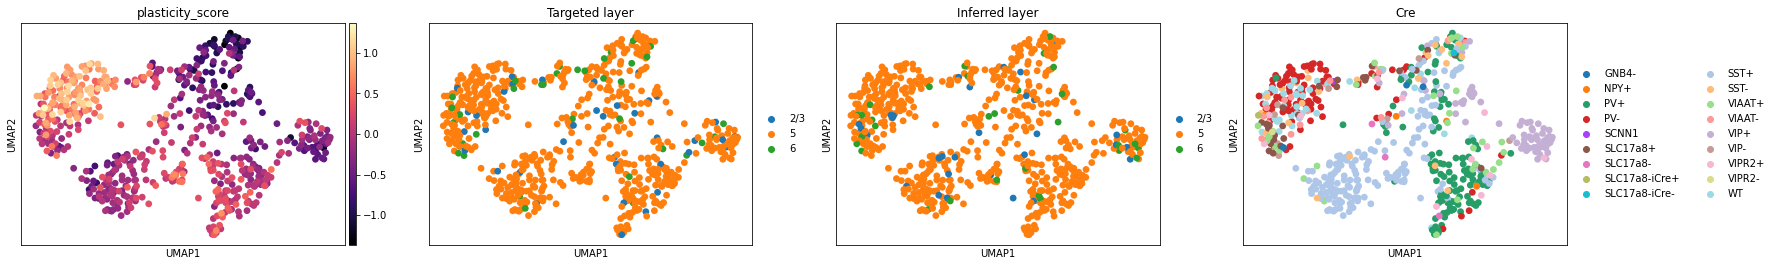

In [13]:
import pandas as pd
import numpy as np
import scanpy as sc

# --- 0) Re-attach metadata to the base AnnData (adata) ---
meta = pd.read_csv("PatchSeqExpression/m1_patchseq_meta_data.csv", sep="\t") \
         .rename(columns={"Cell":"cell_key"}).set_index("cell_key")

# join only new columns to avoid overlap errors
new_cols = [c for c in meta.columns if c not in adata.obs.columns]
adata.obs = adata.obs.join(meta[new_cols], how="left")

# make sure the UMAP object (adata_use) carries obs columns
for c in ["Targeted layer","Inferred layer","Cre","Mouse genotype","plasticity_score"]:
    if c in adata.obs.columns:
        adata_use.obs[c] = adata.obs.loc[adata_use.obs_names, c]

# --- 1) Build a robust L5 mask (numeric or string) ---
def is_layer5(series):
    s = series.copy()
    # try numeric equality
    num = pd.to_numeric(s, errors="coerce")
    m_num = (num == 5)
    # string contains whole-word '5'
    s = s.astype(str)
    m_str = s.str.contains(r"\b5\b", na=False)
    return m_num.fillna(False) | m_str

m_L5 = is_layer5(adata_use.obs.get("Inferred layer", np.nan)) \
    |  is_layer5(adata_use.obs.get("Targeted layer", np.nan))

# --- 2) (Optional) PT-leaning Cre mask ---
pt_cre_pat = r"(fezf2|sim1|bcl11b|ctip2|tbr1|glt25d2)"
m_PT = adata_use.obs.get("Cre", "").astype(str).str.contains(pt_cre_pat, case=False, na=False)

# Choose your subset:
#   L5-only:
adata_l5 = adata_use[m_L5].copy()
#   L5-PT (comment out if you just want L5):
# adata_l5 = adata_use[m_L5 & m_PT].copy()

print("L5 cells:", adata_l5.n_obs)

# --- 3) Re-embed the subset (recommended) ---
sc.pp.scale(adata_l5, zero_center=False)
sc.tl.pca(adata_l5, n_comps=30)
sc.pp.neighbors(adata_l5, n_pcs=30)
sc.tl.umap(adata_l5)

sc.pl.umap(adata_l5, color=["plasticity_score","Targeted layer","Inferred layer","Cre"], cmap="magma")


Unique Targeted layer: ['1', '2/3', '5', '6']
Unique Inferred layer: ['1', '2/3', '5', '6']
N target L5: 576  | N inferred L5: 586  | N union L5: 650  | N target-only: 64  | N inferred-only: 74
L5 cells (Targeted layer==5): 576


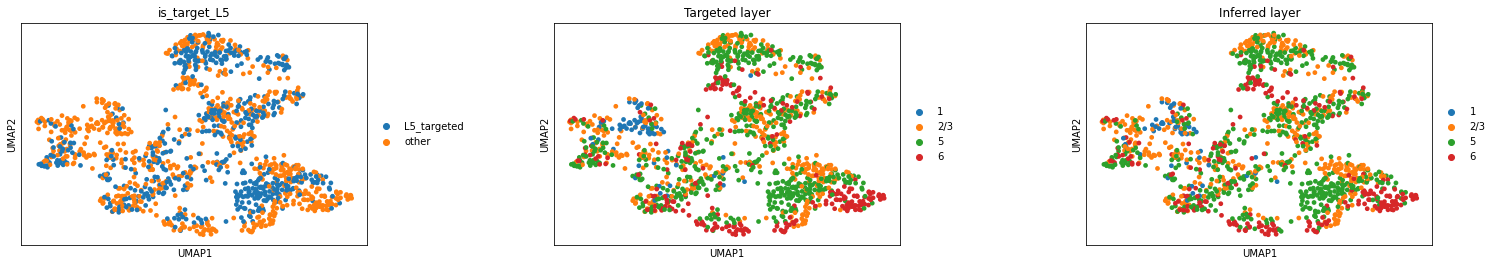

In [15]:
import pandas as pd
import numpy as np
import scanpy as sc

# 0) Quick audit of layer fields
print("Unique Targeted layer:", sorted(adata_use.obs["Targeted layer"].astype(str).unique()))
print("Unique Inferred layer:", sorted(adata_use.obs["Inferred layer"].astype(str).unique()))

# 1) Exact “Targeted layer == 5” mask (robust to numeric/string)
def is_layer5(series):
    s = pd.Series(series, copy=False)
    num = pd.to_numeric(s, errors="coerce")
    m_num = (num == 5)
    m_str = s.astype(str).str.contains(r"\b5\b", na=False)
    return m_num.fillna(False) | m_str

m_target5  = is_layer5(adata_use.obs.get("Targeted layer"))
m_infer5   = is_layer5(adata_use.obs.get("Inferred layer"))
m_L5_union = m_target5 | m_infer5

print(
    f"N target L5: {m_target5.sum()}  | "
    f"N inferred L5: {m_infer5.sum()}  | "
    f"N union L5: {m_L5_union.sum()}  | "
    f"N target-only: {(m_target5 & ~m_infer5).sum()}  | "
    f"N inferred-only: {(~m_target5 & m_infer5).sum()}"
)

# 2) Make the subset using **only targeted layer==5** (as you asked)
adata_l5 = adata_use[m_target5].copy()
print("L5 cells (Targeted layer==5):", adata_l5.n_obs)

# 3) Visual sanity checks
adata_use.obs["is_target_L5"] = np.where(m_target5, "L5_targeted", "other")
sc.pl.umap(adata_use, color=["is_target_L5","Targeted layer","Inferred layer"], wspace=0.4)


Unique Targeted layer: ['1', '2/3', '5', '6']
Unique Inferred layer: ['1', '2/3', '5', '6']
N target L5: 576  | N inferred L5: 586  | N union L5: 650  | N target-only: 64  | N inferred-only: 74
L5 cells (Targeted layer==5): 576


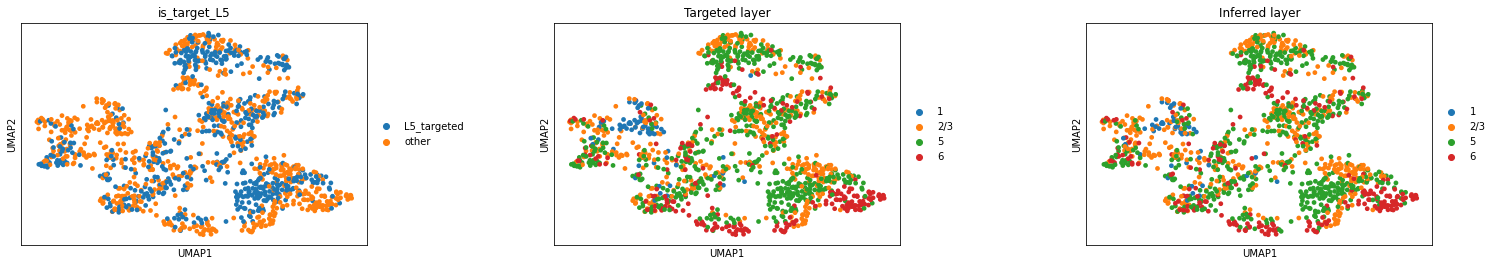

In [16]:
import pandas as pd
import numpy as np
import scanpy as sc

# 0) Quick audit of layer fields
print("Unique Targeted layer:", sorted(adata_use.obs["Targeted layer"].astype(str).unique()))
print("Unique Inferred layer:", sorted(adata_use.obs["Inferred layer"].astype(str).unique()))

# 1) Exact “Targeted layer == 5” mask (robust to numeric/string)
def is_layer5(series):
    s = pd.Series(series, copy=False)
    num = pd.to_numeric(s, errors="coerce")
    m_num = (num == 5)
    m_str = s.astype(str).str.contains(r"\b5\b", na=False)
    return m_num.fillna(False) | m_str

m_target5  = is_layer5(adata_use.obs.get("Targeted layer"))
m_infer5   = is_layer5(adata_use.obs.get("Inferred layer"))
m_L5_union = m_target5 | m_infer5

print(
    f"N target L5: {m_target5.sum()}  | "
    f"N inferred L5: {m_infer5.sum()}  | "
    f"N union L5: {m_L5_union.sum()}  | "
    f"N target-only: {(m_target5 & ~m_infer5).sum()}  | "
    f"N inferred-only: {(~m_target5 & m_infer5).sum()}"
)

# 2) Make the subset using **only targeted layer==5** (as you asked)
adata_l5 = adata_use[m_target5].copy()
print("L5 cells (Targeted layer==5):", adata_l5.n_obs)

# 3) Visual sanity checks
adata_use.obs["is_target_L5"] = np.where(m_target5, "L5_targeted", "other")
sc.pl.umap(adata_use, color=["is_target_L5","Targeted layer","Inferred layer"], wspace=0.4)


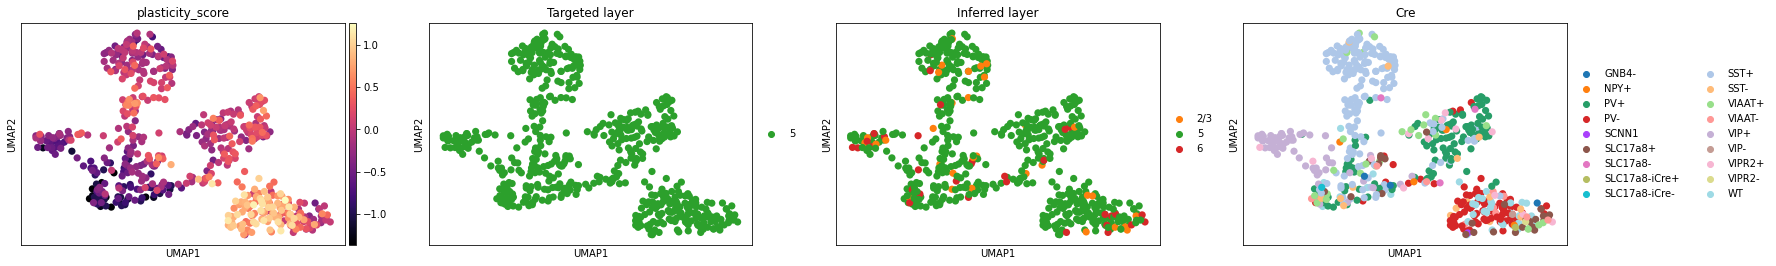

In [24]:
sc.pp.scale(adata_l5, zero_center=False)
sc.tl.pca(adata_l5, n_comps=30)
sc.pp.neighbors(adata_l5, n_pcs=30)
sc.tl.umap(adata_l5)
sc.pl.umap(adata_l5, color=["plasticity_score","Targeted layer","Inferred layer","Cre"], cmap="magma")


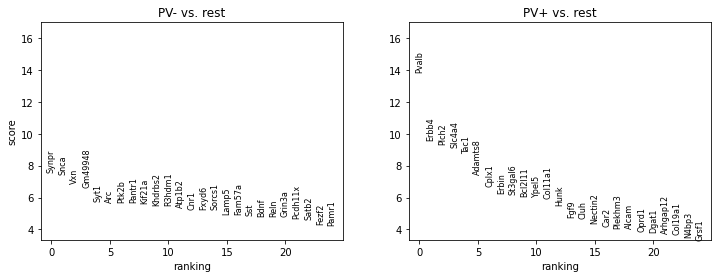

In [27]:
import pandas as pd
import scanpy as sc

# make a 2-level label from Cre
pv_map = {
    "PV+": "PV+",
    "PV-": "PV-",
    # everything else (VIP+, SST+, etc.) -> PV- if you want a broad excitatory+non-PV comparison
}
adata_l5.obs["PV_status"] = adata_l5.obs["Cre"].map(pv_map).fillna("PV-").astype("category")

# (optional) drop rare groups
min_cells = 5
keep = adata_l5.obs["PV_status"].value_counts()
valid_groups = keep[keep >= min_cells].index.tolist()

sc.tl.rank_genes_groups(adata_l5, groupby="PV_status",
                        groups=valid_groups, method="wilcoxon")
sc.pl.rank_genes_groups(adata_l5, groups=valid_groups, n_genes=25)



In [33]:
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

def gene_vec(adata, gene, default=np.nan):
    if gene not in adata.var_names:
        return np.full(adata.n_obs, default, dtype=float)
    X = adata[:, gene].X
    if hasattr(X, "A1"): X = X.A1
    return np.asarray(X, dtype=float)

def cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    gt = (a[:,None] > b).sum(); lt = (a[:,None] < b).sum()
    return (gt - lt) / (a.size * b.size)
adata = adata_l5.copy()  # your L5 subset already

# Excitatory gate: high Slc17a7 & low Gad1/2 (fallback to Cre if genes missing)
slc = gene_vec(adata, "Slc17a7", 0.0)
gad1 = gene_vec(adata, "Gad1",   0.0)
gad2 = gene_vec(adata, "Gad2",   0.0)

# Thresholds that work even with skewed data
slc_thr = np.nanpercentile(slc, 50)         # median
gad_thr = np.nanpercentile(np.r_[gad1,gad2], 25)  # lower quartile

is_excit_marker = (slc >= slc_thr) & (gad1 <= gad_thr) & (gad2 <= gad_thr)

# Optional fallback using Cre: treat PV+ as inhibitory
cre = adata.obs.get("Cre", pd.Series(index=adata.obs_names, dtype=object)).astype(str)
is_excit_cre = cre != "PV+"

is_excit = is_excit_marker | is_excit_cre

# Layer-5 gate (handles '5', 'L5', 'layer 5')
layer_col = "Inferred layer" if "Inferred layer" in adata.obs else "Targeted layer"
is_L5 = adata.obs[layer_col].astype(str).str.contains(r"\b5\b", case=False, regex=True)

adata_excL5 = adata[is_excit & is_L5].copy()
print("L5 excitatory cells:", adata_excL5.n_obs)


ValueError: all the input arrays must have same number of dimensions, but the array at index 0 has 1 dimension(s) and the array at index 1 has 2 dimension(s)

In [32]:
import numpy as np, pandas as pd

# ---- 0) Robust gene vector getter ----
def get_gene_vec(adata, gene_symbol, default_val=0.0):
    """
    Return a 1D float vector for the requested gene, resolving:
    - var_names case/alias (e.g., 'SLC17A7' vs 'Slc17a7')
    - gene symbol columns in .var (e.g., 'gene_symbol','symbols','feature_name')
    - .raw var_names if counts were stashed there
    If nothing matches, returns a constant vector (default_val).
    """
    def _resolve_one(_adata):
        # 1) direct match in var_names (case-insensitive)
        lower_map = {k.lower(): k for k in list(_adata.var_names)}
        hit = lower_map.get(gene_symbol.lower())
        if hit is not None:
            X = _adata[:, hit].X
            return X.A1 if hasattr(X, "A1") else np.asarray(X).ravel()

        # 2) search symbol-ish columns in .var
        cand_cols = [c for c in _adata.var.columns
                     if str(c).lower() in {"gene_symbol","gene_symbols","symbol","symbols","feature_name","gene","name"}]
        for c in cand_cols:
            # map symbol -> var index
            series = _adata.var[c].astype(str).str.lower()
            idx = np.where(series.values == gene_symbol.lower())[0]
            if idx.size:
                j = int(idx[0])
                X = _adata.X[:, j] if _adata.is_view else _adata.X[:, j]
                # safer slice:
                X = _adata[:, _adata.var.index[j]].X
                return X.A1 if hasattr(X, "A1") else np.asarray(X).ravel()

        # 3) fuzzy contains search (last resort)
        for name in list(_adata.var_names):
            if gene_symbol.lower() in str(name).lower():
                X = _adata[:, name].X
                return X.A1 if hasattr(X, "A1") else np.asarray(X).ravel()
        return None

    vec = _resolve_one(adata)
    if vec is None and adata.raw is not None:
        try:
            vec = _resolve_one(adata.raw.to_adata())
        except Exception:
            vec = None
    if vec is None:
        # fall back to a constant vector so downstream code still runs
        vec = np.full(adata.n_obs, float(default_val))
    return vec.astype(float)

# ---- 1) Use multiple excitatory/inhibitory markers (any that exist) ----
slc17a7 = get_gene_vec(adata_l5, "Slc17a7")     # VGlut1 (excitatory cortex)
slc17a6 = get_gene_vec(adata_l5, "Slc17a6")     # VGlut2 (subcortical proj; sometimes present)
slc17a8 = get_gene_vec(adata_l5, "Slc17a8")     # VGlut3 (rare, but harmless)
gad1     = get_gene_vec(adata_l5, "Gad1")       # GABA
gad2     = get_gene_vec(adata_l5, "Gad2")       # GABA

exc_signal = np.nanmax(np.c_[slc17a7, slc17a6, slc17a8], axis=1)  # use whatever exists
inh_signal = np.nanmax(np.c_[gad1, gad2], axis=1)

# adaptive thresholds (robust to scale)
exc_thr = np.nanpercentile(exc_signal, 50)
inh_thr = np.nanpercentile(inh_signal, 25)

is_excit = (exc_signal >= exc_thr) & (inh_signal <= inh_thr)

# ---- 2) Layer-5 gate and projection classes (if available) ----dd
layer_col = "Inferred layer" if "Inferred layer" in adata_l5.obs else "Targeted layer"
is_L5 = adata_l5.obs[layer_col].astype(str).str.contains(r"\b5\b", case=False, regex=True)

if "proj_class" in adata_l5.obs:
    is_proj = adata_l5.obs["proj_class"].isin(["IT","PT","CT"])
else:
    is_proj = pd.Series(True, index=adata_l5.obs_names)

mask_exc_L5 = (is_excit & is_L5.values & is_proj.values)
adata_excL5 = adata_l5[mask_exc_L5].copy()
print("Selected L5 excitatory cells:", adata_excL5.n_obs)
# show a few column candidates that exist in your .var
print([c for c in adata_l5.var.columns if str(c).lower() in
       {"gene_symbol","gene_symbols","symbol","symbols","feature_name","gene","name"}][:5])

# list a few var_names that look like SLC17A7
print([v for v in adata_l5.var_names if "slc17a7".lower() in str(v).lower()][:10])


Selected L5 excitatory cells: 88
[]
[]


In [19]:
# 1) Build a projection-class label (IT/PT/CT)
if "RNA type" in adata_l5.obs.columns:
    proj = adata_l5.obs["RNA type"].astype(str)
else:
    proj = adata_l5.obs["RNA type top-3"].astype(str)

def pick_class(s):
    s = s.upper()
    if "PT" in s: return "PT"
    if "CT" in s: return "CT"
    if "IT" in s: return "IT"
    return np.nan

adata_l5.obs["proj_class"] = proj.map(pick_class)

# Keep only IT/PT/CT
mask_valid = adata_l5.obs["proj_class"].isin(["IT","PT","CT"])
adata_l5c = adata_l5[mask_valid].copy()
print(adata_l5c.obs["proj_class"].value_counts())


IT    115
CT     11
Name: proj_class, dtype: int64


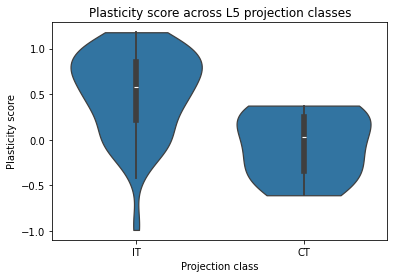

Kruskal–Wallis H=14.10, p=1.732e-04
       pair       U         p  cliffs_delta      q_BH
0  IT vs CT  1067.0  0.000176      0.686957  0.000176


In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import kruskal
import itertools
import numpy as np
import pandas as pd

# 2) Violin/box plot
df = adata_l5c.obs[["proj_class","plasticity_score"]].dropna()
plt.figure(figsize=(6,4))
sns.violinplot(data=df, x="proj_class", y="plasticity_score", inner="box", cut=0)
plt.title("Plasticity score across L5 projection classes")
plt.xlabel("Projection class"); plt.ylabel("Plasticity score")
plt.show()

# 3) Kruskal–Wallis (nonparametric ANOVA)
groups = [df.loc[df.proj_class==g, "plasticity_score"].values for g in ["IT","PT","CT"] if (df.proj_class==g).any()]
H, p = kruskal(*groups)
print(f"Kruskal–Wallis H={H:.2f}, p={p:.3e}")

# 4) Pairwise Wilcoxon rank-sum (Mann–Whitney) with Benjamini–Hochberg FDR
from scipy.stats import mannwhitneyu

pairs = list(itertools.combinations(["IT","PT","CT"], 2))
results = []
for a,b in pairs:
    xa = df.loc[df.proj_class==a, "plasticity_score"].values
    xb = df.loc[df.proj_class==b, "plasticity_score"].values
    if len(xa)>0 and len(xb)>0:
        stat,pv = mannwhitneyu(xa, xb, alternative="two-sided")
        # Cliff's delta effect size
        m = (xa[:,None] > xb[None,:]).mean() - (xa[:,None] < xb[None,:]).mean()
        results.append({"pair": f"{a} vs {b}", "U": stat, "p": pv, "cliffs_delta": m})

res = pd.DataFrame(results)
# BH-FDR
res = res.sort_values("p").reset_index(drop=True)
m = len(res)
res["q_BH"] = res["p"] * (m / (np.arange(m)+1))
res["q_BH"] = res["q_BH"].clip(upper=1)
print(res)


In [21]:
import statsmodels.api as sm

X = pd.DataFrame({
    "is_PT": (adata_l5c.obs["proj_class"]=="PT").astype(int),
    "is_CT": (adata_l5c.obs["proj_class"]=="CT").astype(int),
    "batch": pd.Categorical(adata_l5c.obs.get("Sequencing batch", "unknown")).codes,
    "genes_detected": pd.to_numeric(adata_l5c.obs.get("Number of genes detected"), errors="coerce")
}).fillna(0)

y = adata_l5c.obs["plasticity_score"].values
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary().tables[1])


                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.0231      0.126      0.184      0.855      -0.226       0.272
is_PT           5.289e-14   7.73e-14      0.684      0.495      -1e-13    2.06e-13
is_CT             -0.1793      0.121     -1.485      0.140      -0.418       0.060
batch             -0.0350      0.011     -3.223      0.002      -0.056      -0.013
genes_detected  5.281e-05   8.91e-06      5.929      0.000    3.52e-05    7.04e-05
